
# An analysis of machine learning methods for detection of emission line galaxies

> **Nota:** Este es el codigo principal de mi estudio, sin embargo otros se han creado para el analisis y justificación de algunas partes de la metodologia que serán agregados una vez revisados.
> **Fecha de actualización:** 01/06/2026



## Índice
- [Sección 1: Obtención de datos](#seccion-1)
  - [Igualación de nombre de columnas](#subseccion-1-1)
  - [S/N y otras mascaras](#subseccion-1-2)

- [Sección 2: Diagramas BPT](#seccion-2)
  - [Nuestra clasificación](#subseccion-2-1)
  - [Clasificación hecha por DESI](#subseccion-2-2)
  - [Elección entre clasificadores y nuevas máscaras](#subseccion-2-3)

- [Sección 3: Métodos de machine learning](#seccion-3)
  - [Decission Tree balanced](#subseccion-3-1)
  - [DNN balanced](#subseccion-3-2)
  - [Random Forest balanced](#subseccion-3-3)
  - [XgBoost balanced](#subseccion-3-4)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table
import os
import sys
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import confusion_matrix
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import joblib
import matplotlib.patches as mpatches
from matplotlib.path import Path
import matplotlib.ticker as mticker

plt.rcParams.update({
    'mathtext.fontset': 'cm',  
    'font.family': 'serif',
    'font.size': 46,        # tamaño base
    'axes.titlesize':40,   # títulos
    'axes.labelsize': 40,   # labels de ejes
    'xtick.labelsize': 26,  # números eje x
    'ytick.labelsize': 30,  # números eje y
    'legend.fontsize':20,
    'xtick.major.size': 20,   # longitud ticks mayores eje x
    'ytick.major.size': 20,   # longitud ticks mayores eje y
    'xtick.minor.size': 10,    # longitud ticks menores eje x
    'ytick.minor.size': 10,    # longitud ticks menores eje y

    'xtick.major.width': 4.5, # grosor ticks mayores
    'ytick.major.width': 4.5,
    'xtick.minor.width': 4.0,
    'ytick.minor.width': 4.0
})


<a id="seccion-1"></a>

## 1. Obtención de datos

Los datos espectroscopicos utilizados fueron los siguientes:

- SDSS DR7 MPA-JHU catalog
- SDSS DR12 Portsmouth catalog
- DESI DR1 agn/gal catalog

Todos estos cumplen con la condición de tener disponibles las lineas de emisión con correción de reddening junto a sus respectivos errores disponibles y que hayan observado la zona Stripe 82.



<a id="subseccion-1-1"></a>

### 1.1 "Normalización" de nombres

Dado que fueron obtenidos de 3 catalogos distintos, una manera de agilizar el trabajo fue renombrar todas las columnas siguiendo el formato utilizado por MPA-JHU para los flujos integrados.
Cabe destacar que el catalogo agn/gal de DESI no poseia columnas de errores como yal, si no su varianza inversa tal que:

$$
IV= \frac{1}{\sigma^2}
$$

Para obtener el error $\sigma$ de este catalogo se aplica la siguiente ecuación:

$$
\sigma = \frac{1}{\sqrt{IV}}
$$

Teniendo la precaución de aplicar IV>0 para evitar divisiones por cero o números imaginarios.


In [2]:
rename = {
    'id':'ID',
    'splus_id':'ID',

    'ra':'RA',
    'ra_2':'RA',

    'dec':'DEC',
    'dec_2':'DEC',

    'plate':'plateid',
    'fiberID':'fiberid',

    'HALPHA_FLUX':'h_alpha_flux',
    'Flux_Ha_6562':'h_alpha_flux',
    'H_ALPHA_FLUX':'h_alpha_flux',

    'HALPHA_FLUX_IVAR':'h_alpha_flux_ivar',
    'Flux_Ha_6562_Err':'h_alpha_flux_err',
    'H_ALPHA_FLUX_ERR':'h_alpha_flux_err',

    'HBETA_FLUX':'h_beta_flux',
    'Flux_Hb_4861':'h_beta_flux',
    'H_BETA_FLUX':'h_beta_flux',

    'HBETA_FLUX_IVAR':'h_beta_flux_ivar',
    'Flux_Hb_4861_err':'h_beta_flux_err',
    'H_BETA_FLUX_ERR':'h_beta_flux_err',

    'NII_6584_FLUX':'nii_6584_flux',
    'Flux_NII_6583':'nii_6584_flux',

    'NII_6584_FLUX_IVAR':'nii_6584_flux_ivar',
    'Flux_NII_6583_Err':'nii_6584_flux_err',
    'NII_6584_FLUX_ERR':'nii_6584_flux_err',

    'OI_6300_FLUX':'oi_6300_flux',
    'Flux_OI_6300':'oi_6300_flux',

    'OI_6300_FLUX_IVAR':'oi_6300_flux_ivar',
    'Flux_OI_6300_Err':'oi_6300_flux_err',
    'OI_6300_FLUX_ERR':'oi_6300_flux_err',

    'OIII_5007_FLUX':'oiii_5007_flux',
    'Flux_OIII_5006':'oiii_5007_flux',

    'OIII_5007_FLUX_IVAR':'oiii_5007_flux_ivar',
    'Flux_OIII_5006_Err':'oiii_5007_flux_err',
    'OIII_5007_FLUX_ERR':'oiii_5007_flux_err',

    'SII_6716_FLUX':'sii_6717_flux',
    'Flux_SII_6716':'sii_6717_flux',
    'SII_6717_FLUX':'sii_6717_flux',

    'SII_6716_FLUX_IVAR':'sii_6717_flux_ivar',
    'Flux_SII_6716_Err':'sii_6717_flux_err',
    'SII_6717_FLUX_ERR':'sii_6717_flux_err',

    'SII_6731_FLUX':'sii_6731_flux',
    'Flux_SII_6730':'sii_6731_flux',

    'SII_6731_FLUX_IVAR':'sii_6731_flux_ivar',
    'Flux_SII_6730_Err':'sii_6731_flux_err',
    'SII_6731_FLUX_ERR':'sii_6731_flux_err',

    'spectrotype':'spectype',
    'SPECTYPE':'spectype',

    'Z_1':'Z',
    'z':'Z',

    'z_err':'ZERR',
    'zErr':'ZERR',

    'z_warning':'ZWARN',
    'ZWARN_1':'ZWARN',
    'zwarning':'ZWARN',

    'MEAN_MJD':'MJD',
    'mjd':'MJD',

    '':'w_alpha'
}

cols = ['ID','RA','DEC','Z','ZERR','ZWARN','plateid','fiberid','MJD', 'bptclass', 'bpt','is_nii_sf','is_nii_sy','is_nii_lin','is_nii_comp','is_sii_sf','is_sii_sy','is_sii_lin','is_oi_sf','is_oi_sy','is_oi_lin',
      'h_alpha_flux','h_beta_flux','nii_6584_flux','oi_6300_flux','oiii_5007_flux','sii_6717_flux','sii_6731_flux','h_alpha_flux_err','h_beta_flux_err','nii_6584_flux_err','oi_6300_flux_err','oiii_5007_flux_err','sii_6717_flux_err','sii_6731_flux_err',
      'mag_auto_u','err_mag_auto_u','s2n_auto_u','mag_auto_g','err_mag_auto_g','s2n_auto_g','mag_auto_r','err_mag_auto_r','s2n_auto_r','mag_auto_i','err_mag_auto_i','s2n_auto_i','mag_auto_z','err_mag_auto_z','s2n_auto_z',
      'mag_auto_j0378','err_mag_auto_j0378','s2n_auto_j0378','mag_auto_j0395','err_mag_auto_j0395','s2n_auto_j0395','mag_auto_j0410','err_mag_auto_j0410','s2n_auto_j0410','mag_auto_j0430','err_mag_auto_j0430','s2n_auto_j0430','mag_auto_j0515','err_mag_auto_j0515','s2n_auto_j0515','mag_auto_j0660','err_mag_auto_j0660','s2n_auto_j0660','mag_auto_j0861','err_mag_auto_j0861','s2n_auto_j0861']

def ivar_to_error(df):
    new_cols = {}
    for col in df.columns:
        if "_ivar" in col.lower():
            new_col = col.lower().replace("_ivar", "_err")
            ivar = pd.to_numeric(df[col], errors="coerce")
            err = np.full(len(ivar), np.nan)
            mask = ivar > 0
            err[mask] = 1 / np.sqrt(ivar[mask])
            new_cols[new_col] = err
    for col_name, values in new_cols.items():
        df[col_name] = values
    return df

def fits_to_df(hdu):
    return Table(hdu.data).to_pandas()

def process(fits_path, rename, cols, hdu_indices=None):
    dfs=[]
    with fits.open(fits_path) as hdul:
        if hdu_indices is None:
            indices=[i for i, hdu in enumerate(hdul) if hdu.data is not None]
        else:
            indices= hdu_indices

        print(f"Tablas disponibles:{[f'{i}:{hdul[i].name}'for i in range(len(hdul))]}")
        print(f"Leyendo tablas:{indices}\n")

        for idx in indices:
            df=fits_to_df(hdul[idx])
            df.columns=df.columns.str.strip()
            cols_rename={col:rename[col] for col in df.columns if col in rename}
            df=df.rename(columns=cols_rename)
            df=ivar_to_error(df)

            existing_cols=[c for c in cols if c in df.columns]
            df=df[existing_cols]

            dfs.append(df)
            print(f"HDU{idx}: {len(df)} filas, {len(df.columns)} columnas seleccionadas")

    return dfs

file= r"C:\Users\amand\Desktop\tesis_ama\data\data_all_zwarn.fits"
from astropy.io import fits

with fits.open(file) as hdul:
    names = hdul[1].columns.names
    print(names)
    print("Duplicates:", [n for n in set(names) if names.count(n) > 1])
    print("Blanks/None:", [n for n in names if not n or not isinstance(n, str)])
dfs= process(file, rename, cols, hdu_indices=[1])

for i, df in enumerate(dfs):
    missing= [c for c in cols if c not in df.columns]
    print(f"\nHDU {i+1}:")
    print("Faltan:", missing)

df_final = pd.concat(dfs, ignore_index=True)
df_final.to_csv("dataset_combined_fits.csv", index=False)

print(f"\nShape final: {df_final.shape}")


['TARGETID', 'SURVEY', 'PROGRAM', 'Z_1', 'ZWARN_1', 'SPECTYPE_1', 'AGN_MASKBITS_1', 'OPT_UV_TYPE_1', 'IR_TYPE_1', 'is_nii_sf', 'is_nii_sy', 'is_nii_lin', 'is_nii_comp', 'is_sii_sf', 'is_sii_sy', 'is_sii_lin', 'is_oi_sf', 'is_oi_sy', 'is_oi_lin', 'TARGETID_1', 'SURVEY_1', 'PROGRAM_1', 'HEALPIX', 'Z_2', 'ZERR', 'ZWARN_2', 'SPECTYPE_2', 'AGN_MASKBITS_2', 'OPT_UV_TYPE_2', 'IR_TYPE_2', 'COADD_FIBERSTATUS', 'TARGET_RA', 'TARGET_DEC', 'LS_ID', 'MIN_MJD', 'MEAN_MJD', 'MAX_MJD', 'COADD_NUMEXP', 'COADD_EXPTIME', 'SV_PRIMARY', 'MAIN_PRIMARY', 'ZCAT_PRIMARY', 'DESI_TARGET', 'SCND_TARGET', 'BGS_TARGET', 'CMX_TARGET', 'SV1_DESI_TARGET', 'SV2_DESI_TARGET', 'SV3_DESI_TARGET', 'SV1_BGS_TARGET', 'SV2_BGS_TARGET', 'SV3_BGS_TARGET', 'SV1_SCND_TARGET', 'SV2_SCND_TARGET', 'SV3_SCND_TARGET', 'TARGETID_2', 'SURVEY_2', 'PROGRAM_2', 'LOGMSTAR', 'FLUX_W1', 'FLUX_W2', 'FLUX_W3', 'FLUX_IVAR_W1', 'FLUX_IVAR_W2', 'FLUX_IVAR_W3', 'CIV_1549_FLUX', 'CIV_1549_FLUX_IVAR', 'CIV_1549_SIGMA', 'MGII_2796_FLUX', 'MGII_2796_FL

Los catalogos son juntados en un solo archivo .csv en cual es pasado por TOPCAT donde es aplicado un internal match en base a la ID de SPLUS para eliminar duplicados.

<div align="center">
  <img src="topcat2.png" width="400">
</div>

<a id="subseccion-1-2"></a>

### 1.2 S/N y otras máscaras aplicadas

Está parte del código es interactivo, se pregunta que corte de S/N queremos aplicar tanto para los datos espectrocopicos como para los fotometricos, siedo 0 el valor minimo posible. Se mostrará cuantas galaxias lograron mantenerse sobre el corte. Las ecuaciones utlizadas fueron:

$$
\mathrm{S/N= \frac{Flux}{\sigma_{flux}}}
$$
$$
\mathrm{S/N= \frac{Magnitude}{\sigma_{magnitude}}}
$$

Realice de esta manera el codigo para realizar multiples pruebas variando entre diversos S/N de forma eficiente.

Otras máscaras aplicadas fueron "ZWARN", y ".dropna(subset=bands)" donde se pide que se mantengan solo las galaxias que tengan mediciones de redshift validas y que posean datos validos en todas las bandas fotometricas.


In [3]:
bands=['mag_auto_u','mag_auto_r','mag_auto_g','mag_auto_i','mag_auto_z','mag_auto_j0378','mag_auto_j0395','mag_auto_j0410','mag_auto_j0430','mag_auto_j0515','mag_auto_j0660','mag_auto_j0861']

df=pd.read_csv(r"C:\Users\amand\Desktop\tesis_ama\data\all_data_zwarn.csv")

new_cols={}

for col in df.columns:
    if col.lower().endswith('_flux'):
        err_col= col + '_err'
        snr_col= col.replace('_flux', '_snr')

        if err_col in df.columns:
            flux= pd.to_numeric(df[col], errors="coerce")
            err= pd.to_numeric(df[err_col], errors="coerce")
            snr= np.full(len(df),np.nan)
            mask_valid= err>0
            snr[mask_valid]=flux[mask_valid]/err[mask_valid]
            new_cols[snr_col]=snr

            print("Signal to noise calculado:", snr_col)
df= pd.concat([df, pd.DataFrame(new_cols)], axis=1)

col = "ZWARN"
df[col] = pd.to_numeric(df[col], errors="coerce")
df_zvalid = df[df[col] == 0]

df_clean= df_zvalid.dropna(subset=bands)

print("")
print("Número de galaxias con datos fotometricos validos:", len(df_clean))
print("")

def cut(mensaje, default, minimo=0.0):
    while True:
        try:
            entrada= input(f"{mensaje}[{default}]: ").strip()
            if entrada == '':
                return default
            valor= float(entrada)
            if valor < minimo:
                print(f"Pruebe un número mayor a {minimo}!!")
                continue
            return valor
        except ValueError:
            print("Ingrese un número valido")

# def aplication(df_clean, snr_cut, s2n_cut, snr_cols, s2n_cols):
#     mask=pd.Series(True, index=df_clean.index)

#     if snr_cols:
#         mask &= (df_clean[snr_cols] > snr_cut).all(axis=1)
#     if s2n_cols:
#         mask &= (df_clean[s2n_cols] > s2n_cut).all(axis=1)

#     return df_clean[mask]

def aplication(df_clean, snr_cut, s2n_cut, snr_cols, s2n_cols, snr_cut_weak=3.0):

    weak_lines = ['oiii_5007_snr', 'h_beta_snr']
    weak_cols  = [c for c in snr_cols if c in weak_lines]
    strong_cols = [c for c in snr_cols if c not in weak_lines]
    
    mask = pd.Series(True, index=df_clean.index)
    
    if strong_cols:
        mask &= (df_clean[strong_cols] > snr_cut).all(axis=1)

    if weak_cols:
        mask &= (df_clean[weak_cols] > snr_cut_weak).all(axis=1)

    if s2n_cols:
        mask &= (df_clean[s2n_cols] > s2n_cut).all(axis=1)
    
    return df_clean[mask]


snr_cols=[c for c in df_clean.columns if c.lower().endswith('_snr')] #lineas de emision
s2n_cols=[c for c in df_clean.columns if c.lower().startswith('s2n_')] #fotometria

# def main():
#     print("Interactive signal to noise cut")

#     while True:
        
#         snr_cut=cut("Corte de S/N para lineas de emisión", default=5.0)

#         s2n_cut=cut("Corte de S/N para datos fotometricos", default=5.0)

#         df_filt=aplication(df_clean, snr_cut, s2n_cut, snr_cols, s2n_cols)

#         print(f"  Corte aplicado al S/N espectroscopico: {snr_cut} y S/N fotometrico: {s2n_cut}")
#         print("")

#         total     = len(df_clean)
#         retenidas = len(df_filt)
        
#         print(f"\n  Galaxias antes del corte : {total:>7,}")
#         print(f"  Galaxias retenidas       : {retenidas:>7,}  ({retenidas/total*100:.1f}%)")
#         print(f"  Galaxias descartadas     : {total-retenidas:>7,}  ({(total-retenidas)/total*100:.1f}%)\n")

#         df_filt.to_csv("s2n_all.csv", index=False)
#         print("")
#         print("Datos guardados!")

#         break

def main():
    print("Interactive signal to noise cut")
    while True:
        snr_cut= cut("Corte S/N líneas de emisión (general)", default=5.0)
        snr_cut_weak = cut("Corte S/N para [OIII]5007 y Hbeta", default=3.0)
        s2n_cut= cut("Corte S/N fotometría S-PLUS", default=5.0)
        
        df_filt = aplication(df_clean, snr_cut, s2n_cut,
                             snr_cols, s2n_cols,
                             snr_cut_weak=snr_cut_weak)
        
        print(f"  S/N espectroscópico general : {snr_cut}")
        print(f"  S/N [OIII]5007 y Hbeta      : {snr_cut_weak}")
        print(f"  S/N fotométrico             : {s2n_cut}")
        
        total     = len(df_clean)
        retenidas = len(df_filt)
        print(f"\n  Galaxias antes del corte : {total:>7,}")
        print(f"  Galaxias retenidas       : {retenidas:>7,}  ({retenidas/total*100:.1f}%)")
        print(f"  Galaxias descartadas     : {total-retenidas:>7,}  ({(total-retenidas)/total*100:.1f}%)\n")
        
        df_filt.to_csv("s2n_all.csv", index=False)
        print("Datos guardados!")
        break

if __name__ == '__main__':
    main()

C:\Users\amand\AppData\Local\Temp\ipykernel_17568\2394569173.py:3: DtypeWarning: Columns (0: is_nii_sf, 1: is_nii_sy, 2: is_nii_lin, 3: is_nii_comp, 4: is_sii_sf, 5: is_sii_sy, 6: is_sii_lin, 7: is_oi_sf, 8: is_oi_sy, 9: is_oi_lin, 10: bpt) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv(r"C:\Users\amand\Desktop\tesis_ama\data\all_data_zwarn.csv")


Signal to noise calculado: h_alpha_snr
Signal to noise calculado: h_beta_snr
Signal to noise calculado: nii_6584_snr
Signal to noise calculado: oi_6300_snr
Signal to noise calculado: oiii_5007_snr
Signal to noise calculado: sii_6717_snr
Signal to noise calculado: sii_6731_snr

Número de galaxias con datos fotometricos validos: 126322

Interactive signal to noise cut
  S/N espectroscópico general : 3.0
  S/N [OIII]5007 y Hbeta      : 2.0
  S/N fotométrico             : 3.0

  Galaxias antes del corte : 126,322
  Galaxias retenidas       :   7,919  (6.3%)
  Galaxias descartadas     : 118,403  (93.7%)

Datos guardados!


<a id="seccion-2"></a>

## 2. Diagramas BPT
 
<a id="subseccion-2-1"></a>

### 2.1 Nuestra clasificación

La clasificación utilizada por el profesor Roberto agregando el diagrama BPT $\mathrm{[OI]H\alpha \hspace{0.1cm} vs \hspace{0.1cm} [OIII]/H\beta}$

#### 2.1.1 Diagrama NII

- Star-forming vs AGN: $\mathrm{log([OIII]/H\beta)=\frac{0.61}{log([NII]/H\alpha)-0.05}+1.3}$

- Star-forming vs Composite: $\mathrm{log([OIII]/H\beta)=\frac{0.61}{log([NII]/H\alpha)-0.47}+1.19}$

- Seyfert vs LINER: $\mathrm{log([OIII]/H\beta)=1.05 \hspace{0.1cm}log([NII]/H\alpha)+0.45}$

#### 2.1.2 Diagrama SII

- Star-forming vs AGN: $\mathrm{log([OIII]/H\beta)=\frac{0.72}{log([SII]/H\alpha)-0.32}+1.30}$

- Seyfert vs LINER: $\mathrm{log([OIII]/H\beta)=1.89 \hspace{0.1cm}log([SII]/H\alpha)+0.76}$

#### 2.1.3 Diagrama OI

- Star-forming vs AGN: $\mathrm{log([OIII]/H\beta)=\frac{0.73}{log([OI]/H\alpha)+0.59}+1.33}$

- Seyfert vs LINER: $\mathrm{log([OIII]/H\beta)=1.18 \hspace{0.1cm}log([OI]/H\alpha)+1.30}$


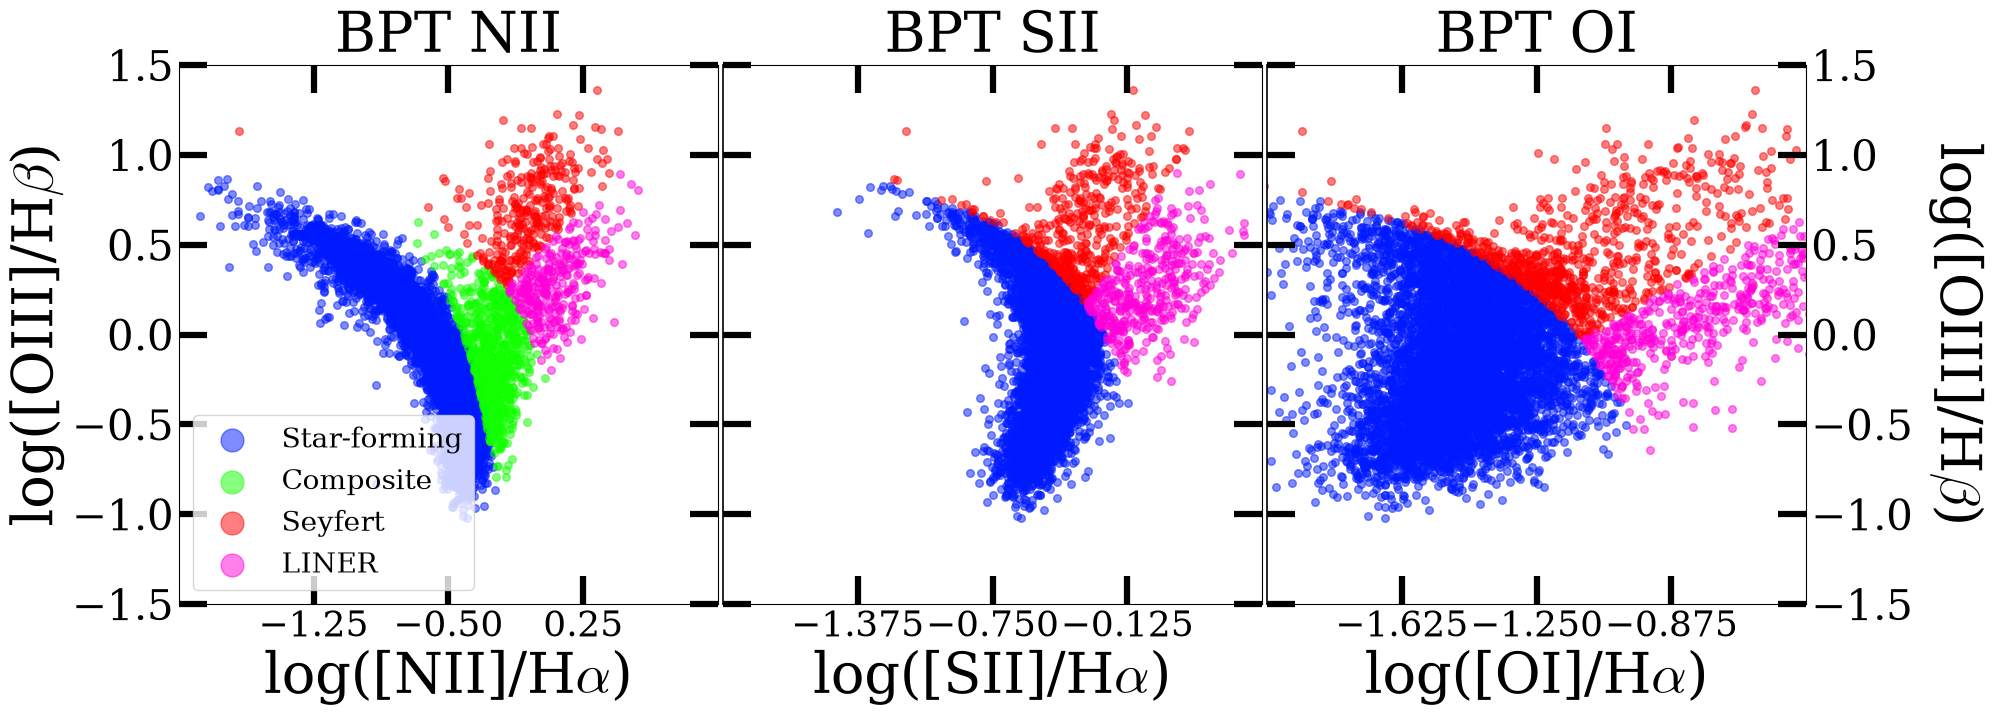

class_nii
Star-forming    6452
Composite        860
Seyfert          309
LINER            298

class_sii
Star-forming    7088
Seyfert          428
LINER            403

class_oi
Star-forming    6608
Seyfert          799
LINER            512



In [4]:
data=pd.read_csv("s2n_all.csv")
data.eval("""
oiii_hb = oiii_5007_flux / h_beta_flux
nii_ha  = nii_6584_flux / h_alpha_flux
sii_ha  = (sii_6717_flux + sii_6731_flux) / h_alpha_flux
oi_ha   = oi_6300_flux / h_alpha_flux
""", inplace=True)

mask = (
    (data['oiii_hb'] > 0) &
    (data['nii_ha'] > 0) &
    (data['sii_ha'] > 0) &
    (data['oi_ha'] > 0)
)

data = data[mask]

data['x1'] = np.log10(data['nii_ha'])
data['x2'] = np.log10(data['sii_ha'])
data['x3'] = np.log10(data['oi_ha'])
data['y'] = np.log10(data['oiii_hb'])

#NII
a= lambda x: 0.61/(x-0.05)+1.3
b= lambda x: 0.61/(x-0.47)+1.19
c= lambda x: 1.05*x+0.45
#SII
d= lambda x: 0.72/(x-0.32)+1.30
e= lambda x: 1.89*x+0.76
#OI
f= lambda x: 0.73/(x+0.59)+1.33
g= lambda x: 1.18*x+1.30
for i, row in data.iterrows():
    x= row['x1']
    y= row['y']

    if x < 0.05:
        y_a= a(x)
    else:
        y_a= np.nan
    if x < 0.47:
        y_b= b(x)
    else:
        y_b= np.nan
    if np.isfinite(y_a) and y_a > y:
        data.loc[i, 'class_nii'] ='Star-forming'
    elif np.isfinite(y_b) and y_b > y:
        data.loc[i, 'class_nii']='Composite'
    else:
        y_c= c(x)
        if y_c < y:
            data.loc[i,'class_nii']='Seyfert'
        else:
            data.loc[i,'class_nii']='LINER'
            
for i, row in data.iterrows():
    x = row['x2']
    y = row['y']

    if x < 0.32:
        y_d= d(x)
    else:
        y_d= np.nan
    if np.isfinite(y_d) and y_d > y:
        data.loc[i, 'class_sii'] = 'Star-forming'
    else:
        y_e = e(x)
        if np.isfinite(y_e):
            if y > y_e:
                data.loc[i, 'class_sii'] = 'Seyfert'
            else:
                data.loc[i, 'class_sii'] = 'LINER'
for i, row in data.iterrows():
    x= row['x3']
    y= row['y']
    
    if x < -0.59:
        y_f=f(x)
    else:
        y_f= np.nan
    if np.isfinite(y_f) and y_f > y:
        data.loc[i, 'class_oi'] = 'Star-forming'
    else:
       
        y_g=g(x)
        if np.isfinite(y_g):
            if y_g < y:
                data.loc[i, 'class_oi']='Seyfert'
            else:
                data.loc[i, 'class_oi']='LINER'

groups = {}

for diag in ['nii', 'sii', 'oi']:
    col = f'class_{diag}'
    groups[diag] = dict(tuple(data.groupby(col)))

fig, ax = plt.subplots(1, 3, figsize=(21, 7), sharey=True)

colors = {'Star-forming':"#001AFFFF",'Composite':"#11FF00FF",'Seyfert':"#FF0000FF",'LINER':"#FF00D9FF"}
# colors = {'Star-forming':'#0B1460FF','Composite':'#209917FF','Seyfert':'#E81414FF','LINER':"#9D0386FF"}


config = {
    'nii': (ax[0], 'x1', 'class_nii', (-2.0,  1.0), r'log([NII]/H$\alpha$)',  'BPT NII'),
    'sii': (ax[1], 'x2', 'class_sii', (-2.0,  0.5), r'log([SII]/H$\alpha$)',  'BPT SII'),
    'oi':  (ax[2], 'x3', 'class_oi',  (-2.0, -0.5), r'log([OI]/H$\alpha$)',   'BPT OI'),
}

for diag, (a_i, col_x, col_class, xlim, xlabel, title) in config.items():

    for colorcito in colors:
        m = data[col_class] == colorcito
        a_i.scatter(
            data[col_x][m], data['y'][m],
            s=30, color=colors[colorcito], alpha=0.5,
            label=colorcito if diag == 'nii' else None   # leyenda solo en panel 0
        )

    a_i.set_xlim(xlim)
    a_i.set_ylim(-1.5, 1.5)
    a_i.set_xlabel(xlabel)
    a_i.set_title(title)

ax[0].set_ylabel(r'log([OIII]/H$\beta$)')

ax[2].yaxis.set_label_position('right')
ax[2].yaxis.tick_right()
ax[2].set_ylabel(r'log([OIII]/H$\beta$)', rotation=270, labelpad=10, va='bottom')

for a_i in ax:
    a_i.tick_params(direction='in', top=True, right=True)
    a_i.spines['top'].set_visible(True)
    a_i.spines['right'].set_visible(True)

for a_i in ax[1:]:
    a_i.tick_params(labelleft=False)

ax[2].yaxis.set_ticks_position('both')
ax[2].tick_params(labelright=True)

ax[1].spines['left'].set_linewidth(1.2)
ax[2].spines['left'].set_linewidth(1.2)

for a_i in ax:
    xmin, xmax = a_i.get_xlim()
    ticks = np.linspace(xmin, xmax, 5)[1:-1]
    a_i.set_xticks(ticks)

plt.subplots_adjust(wspace=0.009)

ax[0].legend(markerscale=3, loc='lower left')


data_myclass=data

change = 'black'

for a_i in ax:

    # Spines (bordes)
    for spine in a_i.spines.values():
        spine.set_color(change)

    # Ticks y números
    a_i.tick_params(
        axis='both',
        colors=change,
        direction='in',
        top=True,
        right=True
    )

    # Labels de ejes
    a_i.xaxis.label.set_color(change)
    a_i.yaxis.label.set_color(change)

    # Título
    a_i.title.set_color(change)

plt.savefig(
    "imagenes/my_class.png",
    dpi=300,
    transparent=False,
    bbox_inches='tight'
)

plt.show()

cols=['class_nii', 'class_sii', 'class_oi']
for col in cols:
    print(data_myclass
          [col].value_counts().to_string())
    print()

data_myclass.to_csv("test_data.csv", index=False)

In [5]:
x_plot = np.linspace(-2, 1, 500)

y_b = b(x_plot)
y_c = c(x_plot)

# encontrar donde la diferencia es mínima
idx_c = np.argmin(np.abs(y_b - y_c))
x_int_c = x_plot[idx_c]
mask_c = x_plot > x_int_c

print(x_int_c)


-0.18436873747494986


(-1.5, 1.5)

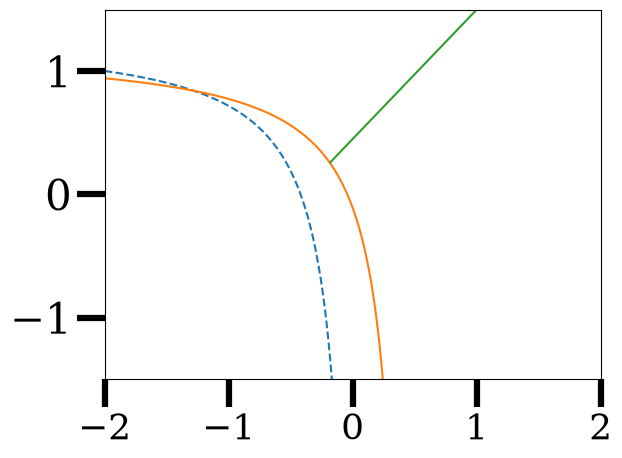

In [6]:
x_kauff = np.linspace(-2, 0.05, 500, endpoint=False)
x_kewley = np.linspace(-2, 0.47, 500, endpoint=False)

plt.plot(x_kauff, a(x_kauff), '--', label='Kauffmann')
plt.plot(x_kewley, b(x_kewley), '-', label='Kewley')
plt.plot(x_plot[mask_c], y_c[mask_c], '-')

plt.xlim(-2,2)
plt.ylim(-1.5,1.5)

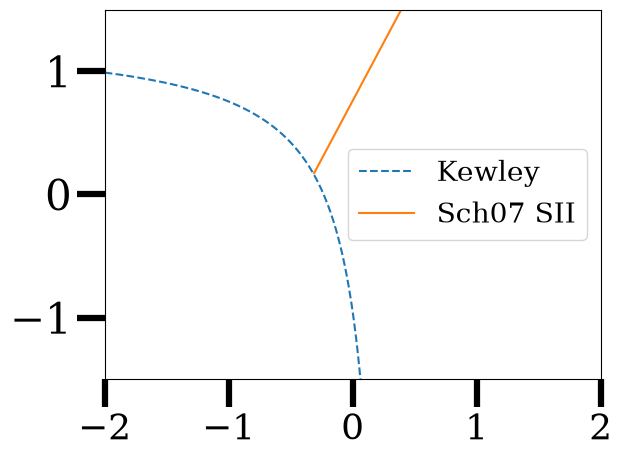

In [7]:
x_ke01_s2=np.linspace(-2, 0.32, 500, endpoint=False)

y_d= d(x_plot)
y_e= e(x_plot)

plt.plot(x_ke01_s2, d(x_ke01_s2), '--', label='Kewley')


# Encontrar el punto final de d dentro del ylim
mask_d_valid = (x_plot < 0.32) & (y_d >= -1.5) & (y_d <= 1.5)
x_end_d = x_plot[mask_d_valid][-1]   # último x válido de d
y_end_d = y_d[mask_d_valid][-1]       # y correspondiente


x_search = np.linspace(-2, 0.319, 10000)
y_d_search = d(x_search)
y_e_search = e(x_search)

# Solo donde ambas son finitas y dentro del ylim
valid = np.isfinite(y_d_search) & np.isfinite(y_e_search) & \
        (y_d_search >= -1.5) & (y_d_search <= 1.5)

idx_int = np.argmin(np.abs(y_d_search[valid] - y_e_search[valid]))
x_int = x_search[valid][idx_int]
y_int = e(x_int)


# Graficar e solo desde esa intersección
mask_e_plot = (x_plot >= x_int) & (y_e >= -1.5) & (y_e <= 1.5)
plt.plot(x_plot[mask_e_plot], y_e[mask_e_plot], '-', label='Sch07 SII')


plt.xlim(-2,2)
plt.ylim(-1.5,1.5)

plt.legend()

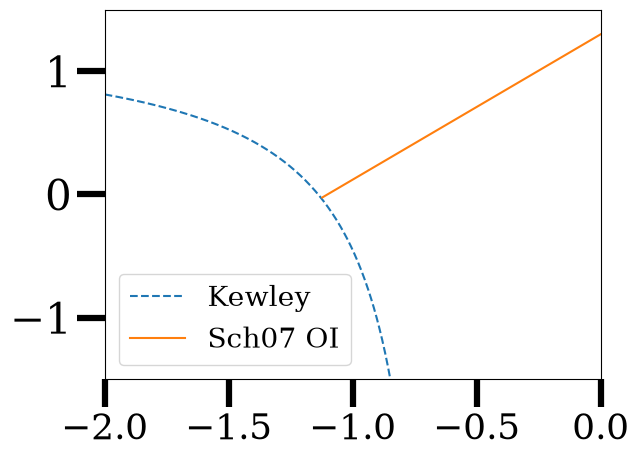

In [8]:
x_ke01_o1=np.linspace(-2, -0.59, 500, endpoint=False)

y_f=f(x_plot)
y_g=g(x_plot)

plt.plot(x_ke01_o1, f(x_ke01_o1), '--', label='Kewley')

mask_f_valid = (x_plot < -0.59) & (y_f >= -1.5) & (y_f <= 2.5)
x_end_f = x_plot[mask_f_valid][-1]   # último x válido de d
y_end_f = y_f[mask_f_valid][-1]       # y correspondiente


x_search = np.linspace(-2, 0.319, 10000)
y_f_search = f(x_search)
y_g_search = g(x_search)

# Solo donde ambas son finitas y dentro del ylim
valid = np.isfinite(y_f_search) & np.isfinite(y_g_search) & \
        (y_f_search >= -1.5) & (y_f_search <= 1.5)

idx_int = np.argmin(np.abs(y_f_search[valid] - y_g_search[valid]))
x_int = x_search[valid][idx_int]
y_int = g(x_int)


# Graficar e solo desde esa intersección
mask_g_plot = (x_plot >= x_int) & (y_g >= -1.5) & (y_g <= 1.5)
plt.plot(x_plot[mask_g_plot], y_g[mask_g_plot], '-', label='Sch07 OI')

plt.xlim(-2,0)
plt.ylim(-1.5,1.5)

plt.legend()

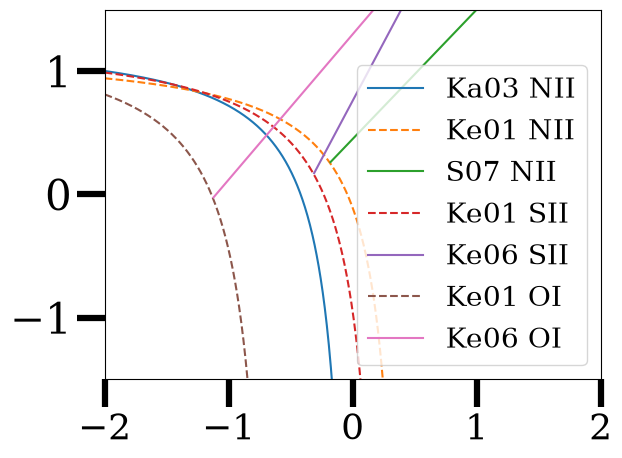

In [9]:
plt.plot(x_kauff, a(x_kauff), '-', label='Ka03 NII')
plt.plot(x_kewley, b(x_kewley), '--', label='Ke01 NII')
plt.plot(x_plot[mask_c], y_c[mask_c], '-', label= 'S07 NII' )

plt.plot(x_ke01_s2, d(x_ke01_s2), '--', label='Ke01 SII')
plt.plot(x_plot[mask_e_plot], y_e[mask_e_plot], '-', label='Ke06 SII')

plt.plot(x_ke01_o1, f(x_ke01_o1), '--', label='Ke01 OI')
plt.plot(x_plot[mask_g_plot], y_g[mask_g_plot], '-', label='Ke06 OI')

plt.xlim(-2,2)
plt.ylim(-1.5,1.5)

plt.legend()

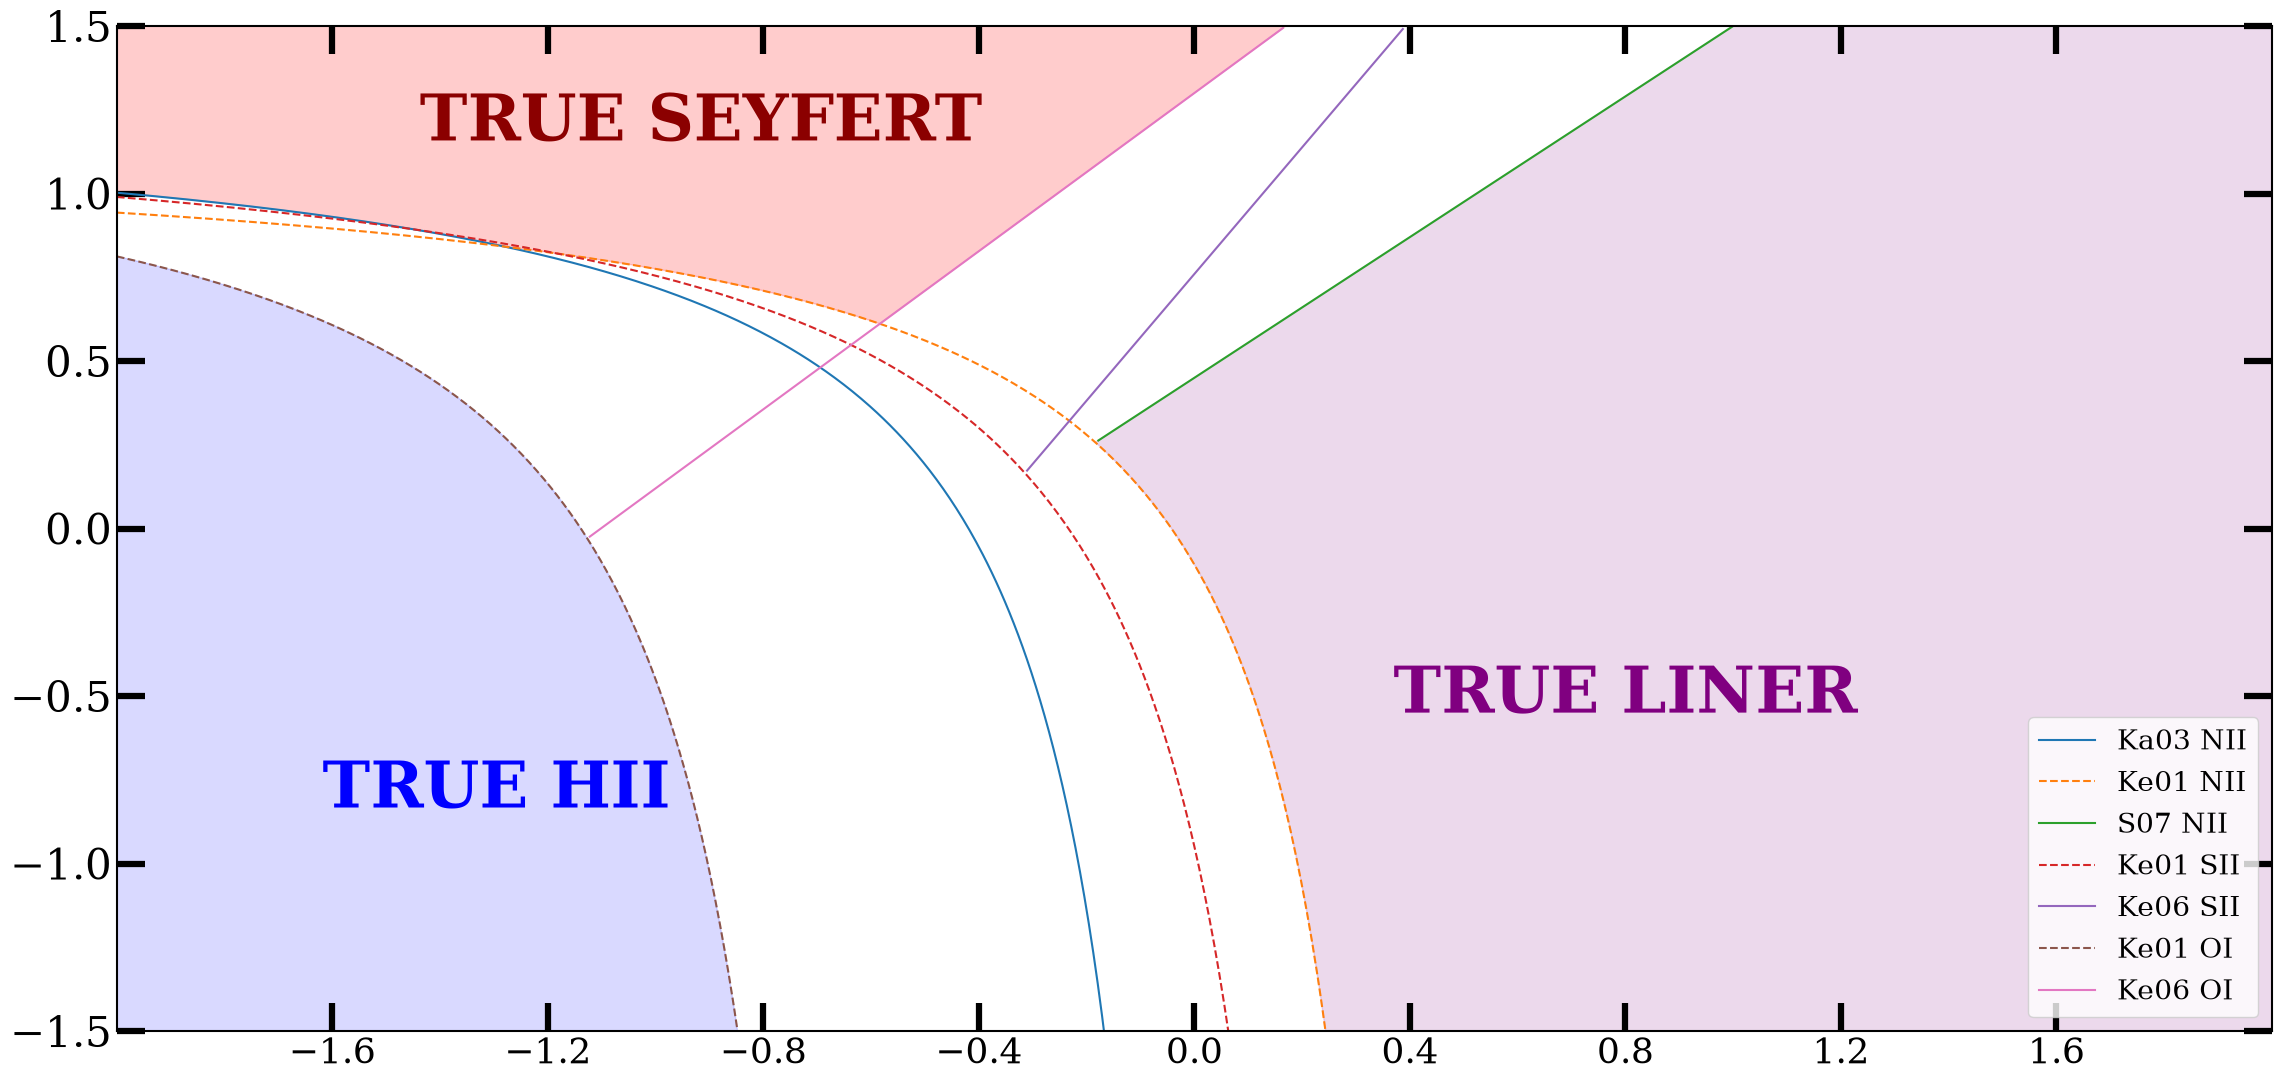

In [10]:
fig, ax = plt.subplots(figsize=(24, 12))

ax.plot(x_kauff, a(x_kauff), '-', label='Ka03 NII')
ax.plot(x_kewley, b(x_kewley), '--', label='Ke01 NII')
ax.plot(x_plot[mask_c], y_c[mask_c], '-', label= 'S07 NII' )

ax.plot(x_ke01_s2, d(x_ke01_s2), '--', label='Ke01 SII')
ax.plot(x_plot[mask_e_plot], y_e[mask_e_plot], '-', label='Ke06 SII')

ax.plot(x_ke01_o1, f(x_ke01_o1), '--', label='Ke01 OI')
ax.plot(x_plot[mask_g_plot], y_g[mask_g_plot], '-', label='Ke06 OI')

x_region = np.linspace(-2, 2, 2000)

y_a_r = np.where(x_region < 0.05, a(x_region), -np.inf)
y_b_r = np.where(x_region < 0.47, b(x_region), -np.inf)
y_g_r = g(x_region)

y_floor_s = np.maximum(np.maximum(y_a_r, y_b_r), y_g_r)
y_floor_s = np.clip(y_floor_s, -1.5, 1.5)

valid_s = (y_floor_s < 1.5) & np.isfinite(y_floor_s)
x_s     = x_region[valid_s]
y_s     = y_floor_s[valid_s]

ax.fill(
    np.concatenate([x_s, x_s[::-1]]),
    np.concatenate([y_s, np.full_like(x_s, 1.5)]),
    color='red', alpha=0.20, zorder=0
)
ax.text(np.mean(x_s), (np.mean(y_s) + 1.5) / 2, 'TRUE SEYFERT',
        ha='center', va='center',
        color='darkred', fontweight='bold')


x1    = np.linspace(-2, 0.47, 2000, endpoint=False)
y_b1  = np.clip(b(x1), -1.5, 1.5)
y_c1  = np.clip(c(x1), -1.5, 1.5)
v1    = y_b1 < y_c1
x1_v  = x1[v1];  y_floor1 = y_b1[v1];  y_ceil1 = y_c1[v1]

x2       = np.linspace(0.47, 2, 2000)
y_c2     = np.clip(c(x2), -1.5, 1.5)
y_floor2 = np.full_like(x2, -1.5)

x_l      = np.concatenate([x1_v,    x2      ])
yfl_l    = np.concatenate([y_floor1, y_floor2])
ycu_l    = np.concatenate([y_ceil1,  y_c2   ])

ax.fill(
    np.concatenate([x_l,    x_l[::-1]  ]),
    np.concatenate([ycu_l,  yfl_l[::-1]]),
    color='purple', alpha=0.15, zorder=0
)
ax.text(0.8, -0.5, 'TRUE LINER',
        ha='center', va='center',
        color='purple', fontweight='bold')


x_h   = np.linspace(-2, -0.59, 2000, endpoint=False)
y_f_h = np.clip(f(x_h), -1.5, 1.5)
v_h   = np.isfinite(y_f_h)
x_hv  = x_h[v_h];  y_fv = y_f_h[v_h]

ax.fill(
    np.concatenate([x_hv,  x_hv[::-1]            ]),
    np.concatenate([y_fv,  np.full_like(x_hv,-1.5)]),
    color='blue', alpha=0.15, zorder=0
)
ax.text(np.mean(x_hv), np.mean((y_fv + (-1.5)) / 2), 'TRUE HII',
        ha='center', va='center',
        color='blue', fontweight='bold')


ax.set_xlim(-2, 2)
ax.set_ylim(-1.5, 1.5)
#ax.set_xlabel(r'log([NII]/H$\alpha$) / log([OI]/H$\alpha$)', fontsize=12)
#ax.set_ylabel(r'log([OIII]/H$\beta$)', fontsize=12)
ax.legend(loc='lower right')
ax.tick_params(direction='in', top=True, right=True, color='black', labelcolor='black')
xticks = np.linspace(-2, 2, 11)   
ax.set_xticks(xticks[1:-1])      
for spine in ax.spines.values():
    spine.set_color('black')
    spine.set_linewidth(1.5)
plt.tight_layout()
plt.savefig(
    "imagenes/mask_class.png",
    dpi=300,
    transparent=False,
    bbox_inches='tight'
)
plt.show()

<a id="subseccion-2-2"></a>

### 2.2 Clasificación hecha por DESI

Basandose en las curvas dichas explicitamente en la pagina https://data.desi.lbl.gov/doc/releases/dr1/vac/agngal/ la diferencia entre este y nuestro clasificador son en las curvas Star-forming vs AGN de los diagramas OI y SII, donde DESI utiliza las descritas por Law et al. 2021

#### 2.1.1 Diagrama NII

- Star-forming vs AGN: $\mathrm{log([OIII]/H\beta)=\frac{0.61}{log([NII]/H\alpha)-0.05}+1.3}$

- Star-forming vs Composite: $\mathrm{log([OIII]/H\beta)=\frac{0.61}{log([NII]/H\alpha)-0.47}+1.19}$

- Seyfert vs LINER: $\mathrm{log([OIII]/H\beta)=1.05 \hspace{0.1cm}log([NII]/H\alpha)+0.45}$

#### 2.1.2 Diagrama SII

- Star-forming vs AGN: $\mathrm{log([OIII]/H\beta)=\frac{0.648}{log([SII]/H\alpha)-0.324}+1.349}$

- Seyfert vs LINER: $\mathrm{log([OIII]/H\beta)=1.89 \hspace{0.1cm}log([SII]/H\alpha)+0.76}$

#### 2.1.3 Diagrama OI

- Star-forming vs AGN: $\mathrm{log([OIII]/H\beta)=\frac{0.884}{log([OI]/H\alpha)+0.124}+1.291}$

- Seyfert vs LINER: $\mathrm{log([OIII]/H\beta)=1.18 \hspace{0.1cm}log([OI]/H\alpha)+1.30}$


 NII

Seyfert
  False Positives (BPT dice, DESI no): 140
  False Negatives (DESI dice, BPT no): 0

Star-forming
  False Positives (BPT dice, DESI no): 3126
  False Negatives (DESI dice, BPT no): 0

LINER
  False Positives (BPT dice, DESI no): 169
  False Negatives (DESI dice, BPT no): 0

 SII

Seyfert
  False Positives (BPT dice, DESI no): 309
  False Negatives (DESI dice, BPT no): 0

Star-forming
  False Positives (BPT dice, DESI no): 3427
  False Negatives (DESI dice, BPT no): 185

LINER
  False Positives (BPT dice, DESI no): 260
  False Negatives (DESI dice, BPT no): 0

 OI

Seyfert
  False Positives (BPT dice, DESI no): 652
  False Negatives (DESI dice, BPT no): 0

Star-forming
  False Positives (BPT dice, DESI no): 3232
  False Negatives (DESI dice, BPT no): 479

LINER
  False Positives (BPT dice, DESI no): 406
  False Negatives (DESI dice, BPT no): 0


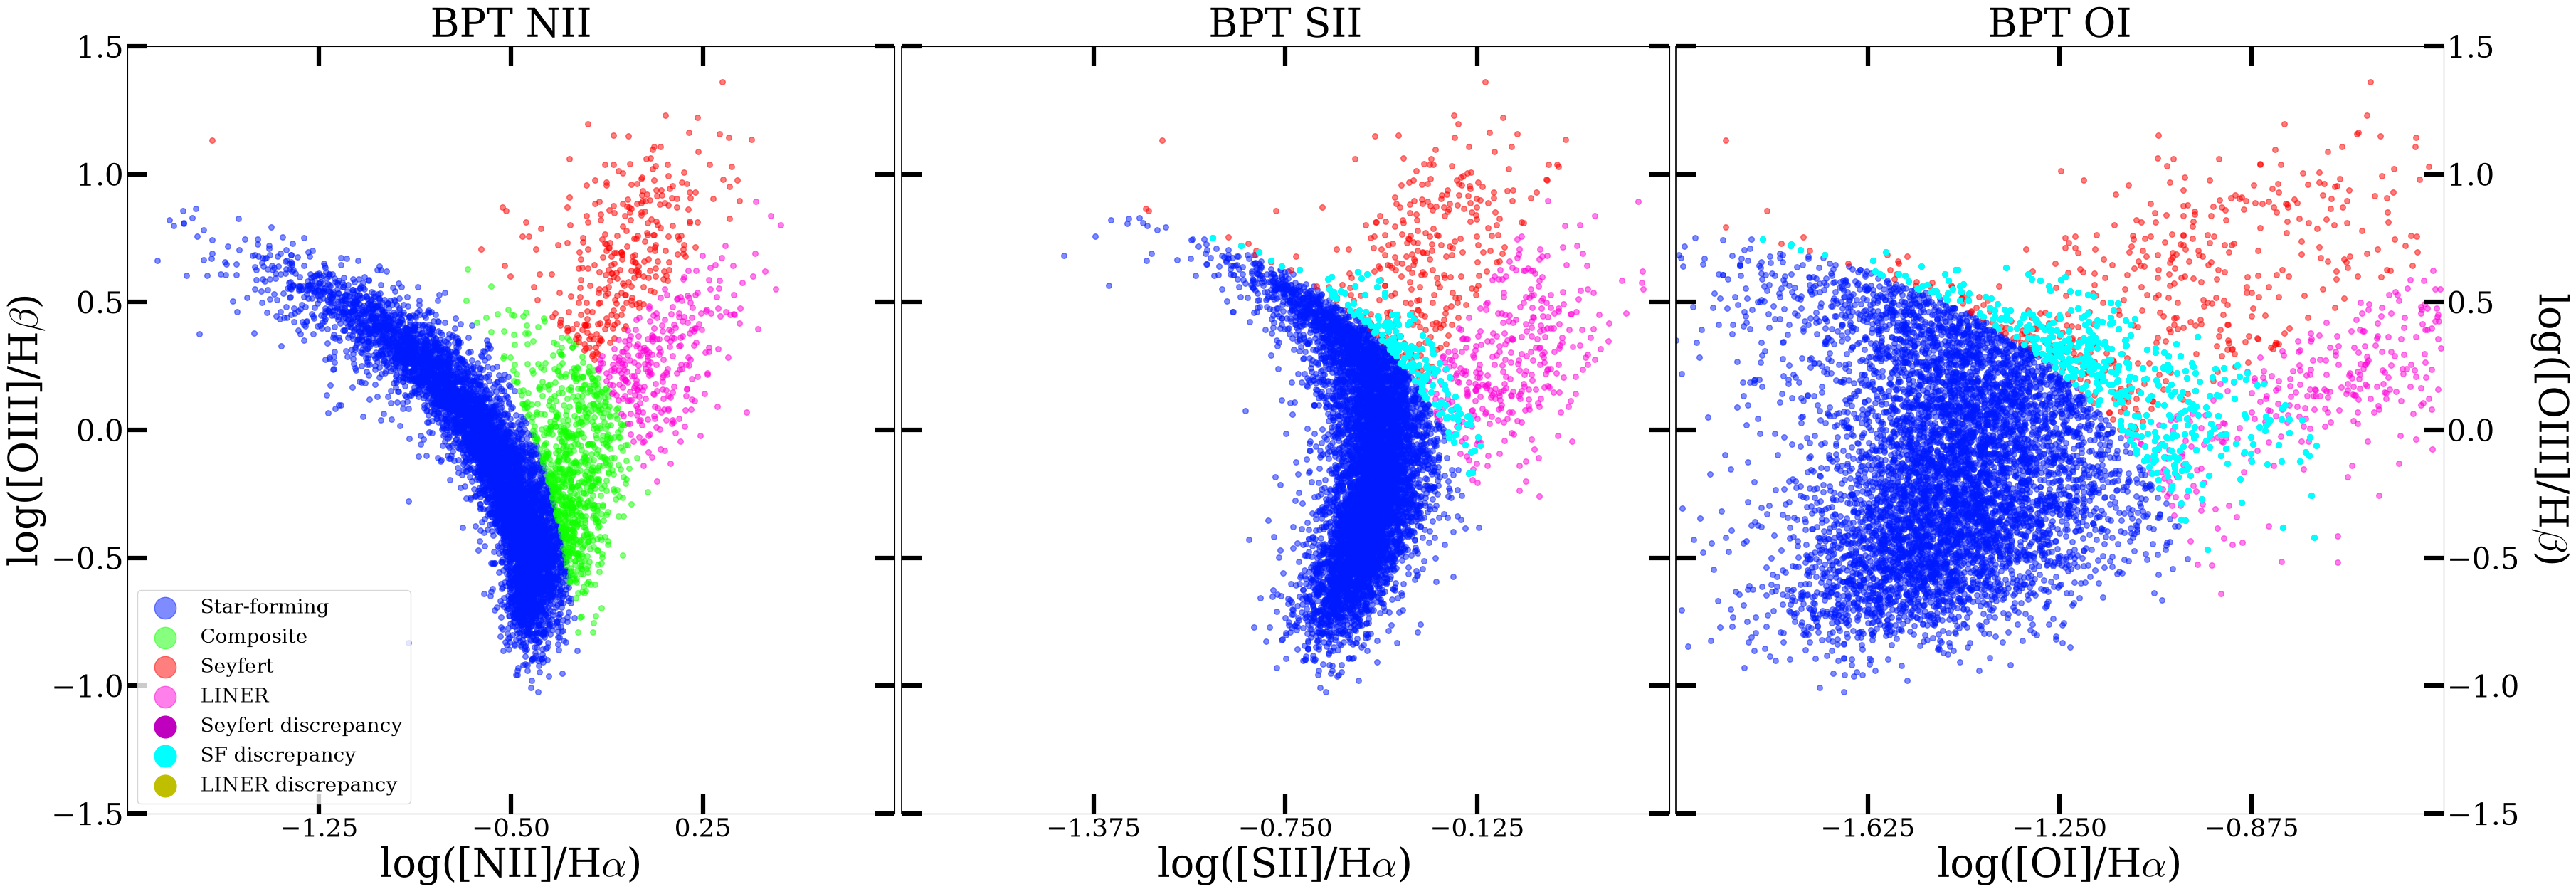

In [11]:
#colors = {'Star-forming':'#0B1460FF','Composite':'#209917FF','Seyfert':'#E81414FF','LINER':'#9D0386FF'}
fig, ax = plt.subplots(1, 3, figsize=(42, 14), sharey=True)
x_n2 = np.linspace(-2, -0.023, 500, endpoint=False)
x_s2 = np.linspace(-2, 0.324, 500, endpoint=False)
x_o1 = np.linspace(-2, -0.124, 500, endpoint=False)

fp_colors = {
    'sy':  'm',
    'sf':  'cyan',
    'lin': 'y'
}

fp_labels = {
    'sy':  'Seyfert discrepancy',
    'sf':  'SF discrepancy',
    'lin': 'LINER discrepancy'
}


registros = []
diagramas = ['nii', 'sii', 'oi']

clases = {
    'sy':  'Seyfert',
    'sf':  'Star-forming',
    'lin': 'LINER'
}

for diag in diagramas:
    print(f'\n {diag.upper()}')

    for short, label in clases.items():

        col_mask  = f'is_{diag}_{short}'   #Asumimos la clasificación de DESI como la correcta
        col_class = f'class_{diag}'        #BPT creado por mi

        #FALSE POSITIVES: BPT dice clase, DESI no
        fp = data[
            (data[col_class] == label) &
            (data[col_mask]  != True)
        ].copy()
        fp['diagrama'] = diag
        fp['clase']    = label
        fp['tipo']     = 'FP'

        #FALSE NEGATIVES: DESI dice clase, BPT no
        fn = data[
            (data[col_mask]  == True) &
            (data[col_class] != label)
        ].copy()
        fn['diagrama'] = diag
        fn['clase']    = label
        fn['tipo']     = 'FN'

        print(f'\n{label}')
        print(f'  False Positives (BPT dice, DESI no): {len(fp)}')
        print(f'  False Negatives (DESI dice, BPT no): {len(fn)}')

        registros.extend([fp, fn])

data_result = pd.concat(registros, ignore_index=True)
data_result.to_csv('discrepancy_clasificacion_corrected.csv', index=False)

df= pd.read_csv(r"discrepancy_clasificacion_corrected.csv")

df_fp= df[df['tipo']=='FP']

def get(diag, short, tipo='FP'):
    label_map={'sy':'Seyfert','sf':'Star-forming', 'lin':'LINER'}
    return df[
        (df['tipo'] == tipo)&
        (df['diagrama'] == diag)&
        (df['clase'] == label_map[short])
    ]

config = {
    'nii': (ax[0], 'x1', 'class_nii', (-2.0,  1.0), r'log([NII]/H$\alpha$)',  'BPT NII'),
    'sii': (ax[1], 'x2', 'class_sii', (-2.0,  0.5), r'log([SII]/H$\alpha$)',  'BPT SII'),
    'oi':  (ax[2], 'x3', 'class_oi',  (-2.0, -0.5), r'log([OI]/H$\alpha$)',   'BPT OI'),
}
    
for diag, (a_i, col_x, col_class, xlim, xlabel, title) in config.items():

    for c in colors:
        m = data[col_class] == c
        a_i.scatter(
            data[col_x][m], data['y'][m],
            s=30, color=colors[c], alpha=0.5,
            label=c if diag == 'nii' else None   
        )

    # Grafico de FP o  FN 
    for short in ['sy', 'sf', 'lin']:
        subset = get(diag, short, tipo='FN')
        a_i.scatter(
            subset[col_x], subset['y'],
            s=30,
            #facecolors='none',
            color=fp_colors[short],
            linewidths=1.2,
            label=fp_labels[short] if diag == 'nii' else None
        )

    a_i.set_xlim(xlim)
    a_i.set_ylim(-1.5, 1.5)
    a_i.set_xlabel(xlabel)
    a_i.set_title(title)

#ax[0].plot(x_n2, l_n2(x_n2)) #curva SF vs AGN de Law et al 2021, la agregue pero DESI no utiliza esta


ax[0].set_ylabel(r'log([OIII]/H$\beta$)')

ax[2].yaxis.set_label_position('right')
ax[2].yaxis.tick_right()
ax[2].set_ylabel(r'log([OIII]/H$\beta$)', rotation=270, labelpad=10, va='bottom')

for a_i in ax:
    a_i.tick_params(direction='in', top=True, right=True)
    a_i.spines['top'].set_visible(True)
    a_i.spines['right'].set_visible(True)

for a_i in ax[1:]:
    a_i.tick_params(labelleft=False)

ax[2].yaxis.set_ticks_position('both')
ax[2].tick_params(labelright=True)

ax[1].spines['left'].set_linewidth(1.2)
ax[2].spines['left'].set_linewidth(1.2)

for a_i in ax:
    xmin, xmax = a_i.get_xlim()
    ticks = np.linspace(xmin, xmax, 5)[1:-1]
    a_i.set_xticks(ticks)

plt.subplots_adjust(wspace=0.009)

ax[0].legend(markerscale=4, loc='lower left')

c = 'black'

for a_i in ax:

    # Spines (bordes)
    for spine in a_i.spines.values():
        spine.set_color(c)

    # Ticks y números
    a_i.tick_params(
        axis='both',
        colors=c,
        direction='in',
        top=True,
        right=True
    )

    # Labels de ejes
    a_i.xaxis.label.set_color(c)
    a_i.yaxis.label.set_color(c)

    # Título
    a_i.title.set_color(c)

# plt.savefig(
#     "imagenes/discrepancy.png",
#     dpi=150,
#     transparent=True,
#     bbox_inches='tight'
# )

plt.show()


 NII

Seyfert
  False Positives (BPT dice, DESI no): 140
  False Negatives (DESI dice, BPT no): 0

Star-forming
  False Positives (BPT dice, DESI no): 3126
  False Negatives (DESI dice, BPT no): 0

LINER
  False Positives (BPT dice, DESI no): 169
  False Negatives (DESI dice, BPT no): 0

 SII

Seyfert
  False Positives (BPT dice, DESI no): 140
  False Negatives (DESI dice, BPT no): 0

Star-forming
  False Positives (BPT dice, DESI no): 3519
  False Negatives (DESI dice, BPT no): 32

LINER
  False Positives (BPT dice, DESI no): 184
  False Negatives (DESI dice, BPT no): 0

 OI

Seyfert
  False Positives (BPT dice, DESI no): 180
  False Negatives (DESI dice, BPT no): 0

Star-forming
  False Positives (BPT dice, DESI no): 3488
  False Negatives (DESI dice, BPT no): 41

LINER
  False Positives (BPT dice, DESI no): 184
  False Negatives (DESI dice, BPT no): 0


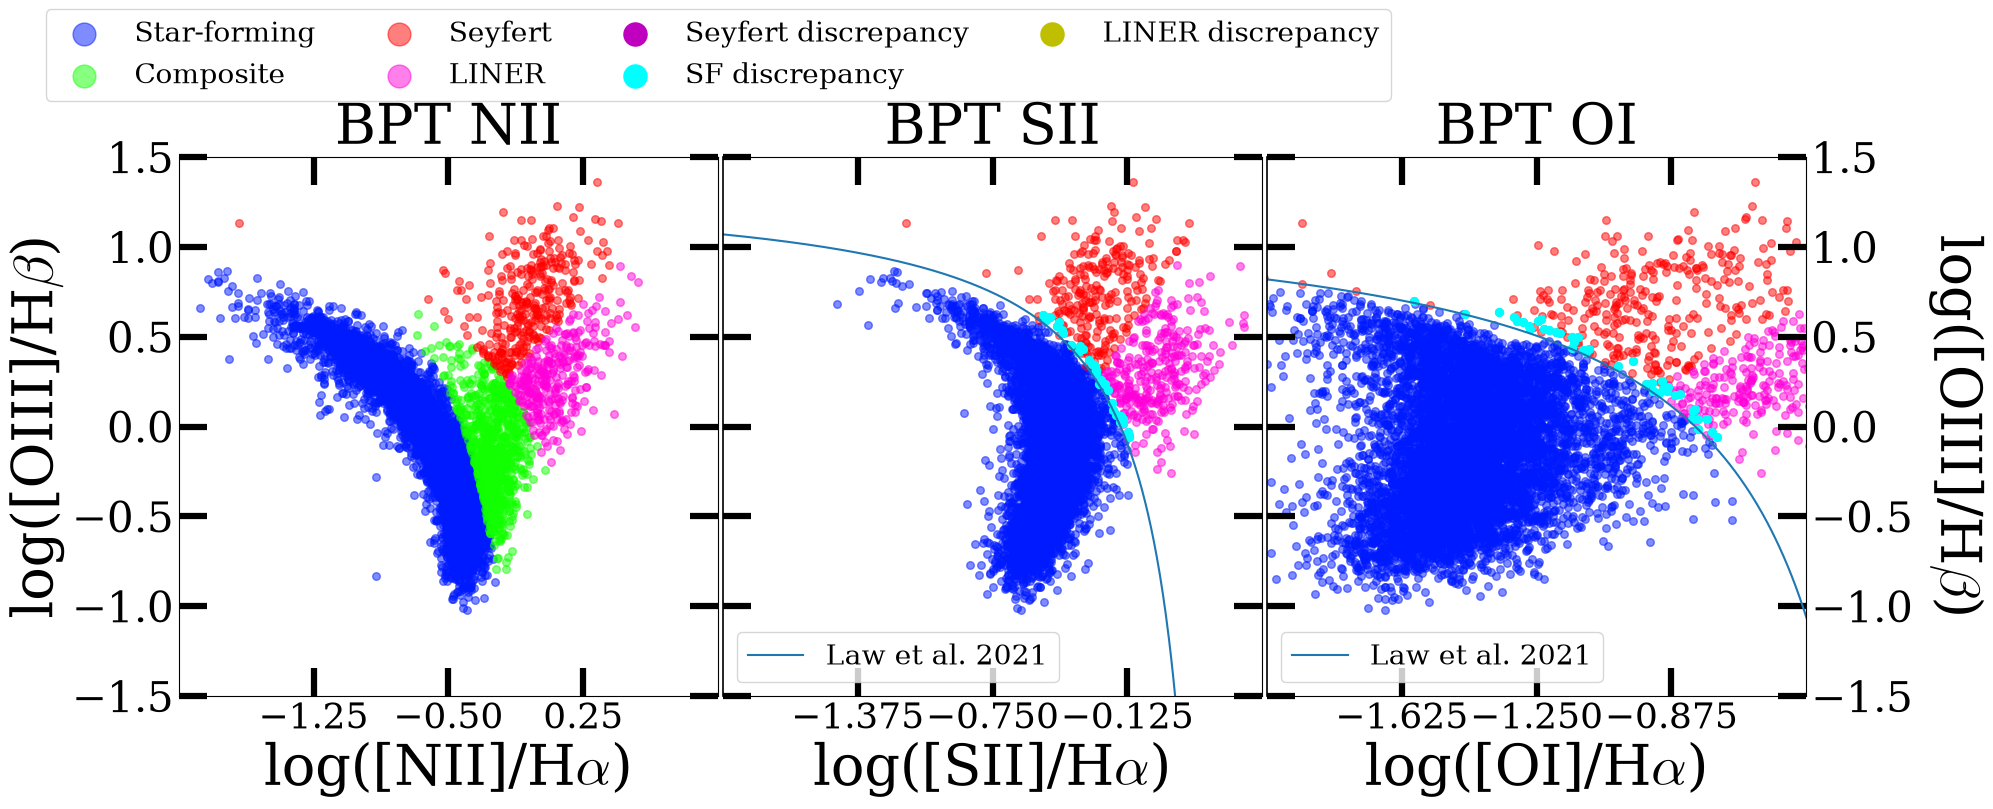

class_nii
Star-forming    6452
Composite        860
Seyfert          309
LINER            298

class_sii
Star-forming    7333
LINER            327
Seyfert          259

class_oi
Star-forming    7302
Seyfert          327
LINER            290



In [12]:
data=pd.read_csv("s2n_all.csv")
data.eval("""
oiii_hb = oiii_5007_flux / h_beta_flux
nii_ha  = nii_6584_flux / h_alpha_flux
sii_ha  = (sii_6717_flux + sii_6731_flux) / h_alpha_flux
oi_ha   = oi_6300_flux / h_alpha_flux
""", inplace=True)

mask = (
    (data['oiii_hb'] > 0) &
    (data['nii_ha']  > 0) &
    (data['sii_ha']  > 0) &
    (data['oi_ha']   > 0)
)

data = data[mask]

data['x1'] = np.log10(data['nii_ha'])
data['x2'] = np.log10(data['sii_ha'])
data['x3'] = np.log10(data['oi_ha'])
data['y']  = np.log10(data['oiii_hb'])

#NII
a= lambda x: 0.61/(x-0.05)+1.3
b= lambda x: 0.61/(x-0.47)+1.19
c= lambda x: 1.05*x+0.45
#SII
d= lambda x: 0.648/(x-0.324)+1.349 #Law et al 2021
e= lambda x: 1.89*x+0.76
#OI
f= lambda x: 0.884/(x+0.124)+1.291 #Law et al 2021
g= lambda x: 1.18*x+1.30

for i, row in data.iterrows():
    x= row['x1']
    y= row['y']

    if x < 0.05:
        y_a= a(x)
    else:
        y_a= np.nan
    if x < 0.47:
        y_b= b(x)
    else:
        y_b= np.nan
    if np.isfinite(y_a) and y_a >= y:
        data.loc[i, 'class_nii'] ='Star-forming'
    elif np.isfinite(y_b) and y_b > y:
        data.loc[i, 'class_nii']='Composite'
    else:
        y_c= c(x)
        if y_c < y:
            data.loc[i,'class_nii']='Seyfert'
        else:
            data.loc[i,'class_nii']='LINER'

sf_nii   = data[data['class_nii'] == 'Star-forming']
comp_nii = data[data['class_nii'] == 'Composite']
sey_nii  = data[data['class_nii'] == 'Seyfert']
lin_nii = data[data['class_nii'] == 'LINER']
data['class_sii'] = None

for i, row in data.iterrows():
    x = row['x2']
    y = row['y']

    if x < 0.324:
        y_d= d(x)
    else:
        y_d= np.nan
    if np.isfinite(y_d) and y_d > y:
        data.loc[i, 'class_sii'] = 'Star-forming'
    else:
        y_e = e(x)
        if np.isfinite(y_e):
            if y > y_e:
                data.loc[i, 'class_sii'] = 'Seyfert'
            else:
                data.loc[i, 'class_sii'] = 'LINER'

sf_sii   = data[data['class_sii'] == 'Star-forming']
sey_sii  = data[data['class_sii'] == 'Seyfert']
lin_sii = data[data['class_sii'] == 'LINER']
for i, row in data.iterrows():
    x= row['x3']
    y= row['y']
    
    if x < -0.124:
        y_f=f(x)
    else:
        y_f= np.nan
    if np.isfinite(y_f) and y_f > y:
        data.loc[i, 'class_oi'] = 'Star-forming'
    else:
       
        y_g=g(x)
        if np.isfinite(y_g):
            if y_g < y:
                data.loc[i, 'class_oi']='Seyfert'
            else:
                data.loc[i, 'class_oi']='LINER'

sf_oi   = data[data['class_oi'] == 'Star-forming']
sey_oi  = data[data['class_oi'] == 'Seyfert']
lin_oi = data[data['class_oi'] == 'LINER']


#colors = {'Star-forming':'#0B1460FF','Composite':'#209917FF','Seyfert':'#E81414FF','LINER':'#9D0386FF'}
fig, ax = plt.subplots(1, 3, figsize=(21, 7), sharey=True)
x_n2 = np.linspace(-2, -0.023, 500, endpoint=False)
x_s2 = np.linspace(-2, 0.324, 500, endpoint=False)
x_o1 = np.linspace(-2, -0.124, 500, endpoint=False)

registros = []
fp_colors = {
    'sy':  'm',
    'sf':  'cyan',
    'lin': 'y'
}

fp_labels = {
    'sy':  'Seyfert discrepancy',
    'sf':  'SF discrepancy',
    'lin': 'LINER discrepancy'
}

for diag in diagramas:
    print(f'\n {diag.upper()}')

    for short, label in clases.items():

        col_mask  = f'is_{diag}_{short}'   #Asumimos la clasificación de DESI como la correcta
        col_class = f'class_{diag}'        #BPT creado por mi

        #FALSE POSITIVES: BPT dice clase, DESI no
        fp = data[
            (data[col_class] == label) &
            (data[col_mask]  != True)
        ].copy()
        fp['diagrama'] = diag
        fp['clase']    = label
        fp['tipo']     = 'FP'

        #FALSE NEGATIVES: DESI dice clase, BPT no
        fn = data[
            (data[col_mask]  == True) &
            (data[col_class] != label)
        ].copy()
        fn['diagrama'] = diag
        fn['clase']    = label
        fn['tipo']     = 'FN'

        print(f'\n{label}')
        print(f'  False Positives (BPT dice, DESI no): {len(fp)}')
        print(f'  False Negatives (DESI dice, BPT no): {len(fn)}')

        registros.extend([fp, fn])

data_result = pd.concat(registros, ignore_index=True)
data_result.to_csv('discrepancy_clasificacion_corrected.csv', index=False)

df= pd.read_csv(r"discrepancy_clasificacion_corrected.csv")

df_fp= df[df['tipo']=='FP']



def get(diag, short, tipo='FP'):
    label_map={'sy':'Seyfert','sf':'Star-forming', 'lin':'LINER'}
    return df[
        (df['tipo'] == tipo)&
        (df['diagrama'] == diag)&
        (df['clase'] == label_map[short])
    ]

config = {
    'nii': (ax[0], 'x1', 'class_nii', (-2.0,  1.0), r'log([NII]/H$\alpha$)',  'BPT NII'),
    'sii': (ax[1], 'x2', 'class_sii', (-2.0,  0.5), r'log([SII]/H$\alpha$)',  'BPT SII'),
    'oi':  (ax[2], 'x3', 'class_oi',  (-2.0, -0.5), r'log([OI]/H$\alpha$)',   'BPT OI'),
}
    
for diag, (a_i, col_x, col_class, xlim, xlabel, title) in config.items():

    for colorcito in colors:
        m = data[col_class] == colorcito
        a_i.scatter(
            data[col_x][m], data['y'][m],
            s=30, color=colors[colorcito], alpha=0.5,
            label=colorcito if diag == 'nii' else None   
        )

    # Grafico de FP o  FN 
    for short in ['sy', 'sf', 'lin']:
        subset = get(diag, short, tipo='FN')
        a_i.scatter(
            subset[col_x], subset['y'],
            s=30,
            #facecolors='none',
            color=fp_colors[short],
            linewidths=1.2,
            label=fp_labels[short] if diag == 'nii' else None
        )

    a_i.set_xlim(xlim)
    a_i.set_ylim(-1.5, 1.5)
    a_i.set_xlabel(xlabel)
    a_i.set_title(title)

#ax[0].plot(x_n2, l_n2(x_n2)) #curva SF vs AGN de Law et al 2021, la agregue pero DESI no utiliza esta
ax[1].plot(x_s2, d(x_s2), label='Law et al. 2021')
ax[2].plot(x_o1, f(x_o1), label='Law et al. 2021')

ax[0].set_ylabel(r'log([OIII]/H$\beta$)')

ax[2].yaxis.set_label_position('right')
ax[2].yaxis.tick_right()
ax[2].set_ylabel(r'log([OIII]/H$\beta$)', rotation=270, labelpad=10, va='bottom')

for a_i in ax:
    a_i.tick_params(direction='in', top=True, right=True)
    a_i.spines['top'].set_visible(True)
    a_i.spines['right'].set_visible(True)

for a_i in ax[1:]:
    a_i.tick_params(labelleft=False)

ax[2].yaxis.set_ticks_position('both')
ax[2].tick_params(labelright=True)

ax[1].spines['left'].set_linewidth(1.2)
ax[2].spines['left'].set_linewidth(1.2)

for a_i in ax:
    xmin, xmax = a_i.get_xlim()
    ticks = np.linspace(xmin, xmax, 5)[1:-1]
    a_i.set_xticks(ticks)

plt.subplots_adjust(wspace=0.009)

ax[0].legend(markerscale=3,bbox_to_anchor=(1.0, 1.30),ncol=4, loc='upper center')
ax[1].legend(markerscale=4, loc='lower left')
ax[2].legend(markerscale=4, loc='lower left')

change = 'black'

for a_i in ax:

    # Spines (bordes)
    for spine in a_i.spines.values():
        spine.set_color(change)

    # Ticks y números
    a_i.tick_params(
        axis='both',
        colors=change,
        direction='in',
        top=True,
        right=True
    )

    # Labels de ejes
    a_i.xaxis.label.set_color(change)
    a_i.yaxis.label.set_color(change)

    # Título
    a_i.title.set_color(change)

plt.savefig(
    "imagenes/desi_class.png",
    dpi=150,
    transparent=True,
    bbox_inches='tight'
)

plt.show()

data_desiclass=data

cols=['class_nii', 'class_sii', 'class_oi']
for col in cols:
    print(data_desiclass
          [col].value_counts().to_string())
    print()

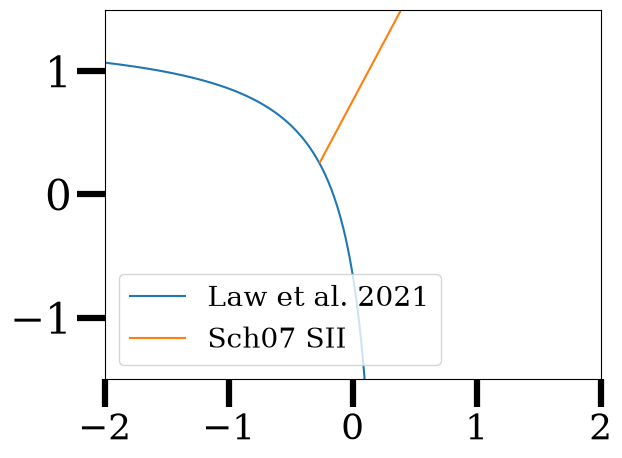

In [13]:
y_d= d(x_plot)
y_e= e(x_plot)

plt.plot(x_s2, d(x_s2), label='Law et al. 2021')

# Encontrar el punto final de d dentro del ylim
mask_d_valid = (x_plot < 0.324) & (y_d >= -1.5) & (y_d <= 1.5)
x_end_d = x_plot[mask_d_valid][-1]   # último x válido de d
y_end_d = y_d[mask_d_valid][-1]       # y correspondiente


x_search = np.linspace(-2, 0.319, 10000)
y_d_search = d(x_search)
y_e_search = e(x_search)

# Solo donde ambas son finitas y dentro del ylim
valid = np.isfinite(y_d_search) & np.isfinite(y_e_search) & \
        (y_d_search >= -1.5) & (y_d_search <= 1.5)

idx_int = np.argmin(np.abs(y_d_search[valid] - y_e_search[valid]))
x_int = x_search[valid][idx_int]
y_int = e(x_int)


# Graficar e solo desde esa intersección
mask_e_plot = (x_plot >= x_int) & (y_e >= -1.5) & (y_e <= 1.5)
plt.plot(x_plot[mask_e_plot], y_e[mask_e_plot], '-', label='Sch07 SII')


plt.xlim(-2,2)
plt.ylim(-1.5,1.5)

plt.legend()

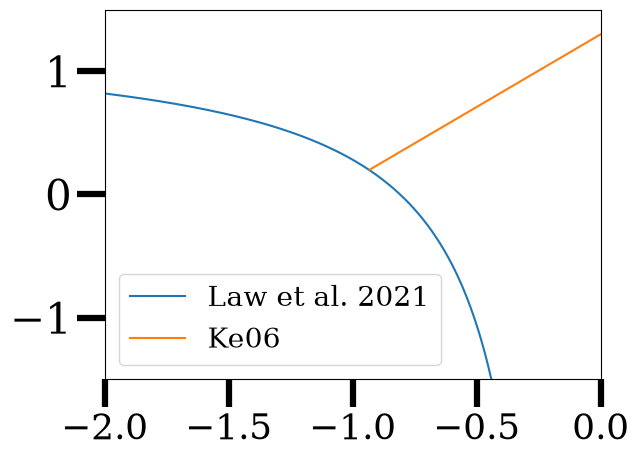

In [14]:
y_f=f(x_plot)
y_g=g(x_plot)

plt.plot(x_o1, f(x_o1), label='Law et al. 2021')

mask_f_valid = (x_plot < -0.124) & (y_f >= -1.5) & (y_f <= 2.5)
x_end_f = x_plot[mask_f_valid][-1]   # último x válido de d
y_end_f = y_f[mask_f_valid][-1]       # y correspondiente


x_search = np.linspace(-2, 0.319, 10000)
y_f_search = f(x_search)
y_g_search = g(x_search)

# Solo donde ambas son finitas y dentro del ylim
valid = np.isfinite(y_f_search) & np.isfinite(y_g_search) & \
        (y_f_search >= -1.5) & (y_f_search <= 1.5)

idx_int = np.argmin(np.abs(y_f_search[valid] - y_g_search[valid]))
x_int = x_search[valid][idx_int]
y_int = g(x_int)


# Graficar e solo desde esa intersección
mask_g_plot = (x_plot >= x_int) & (y_g >= -1.5) & (y_g <= 1.5)
plt.plot(x_plot[mask_g_plot], y_g[mask_g_plot], '-', label='Ke06')

plt.xlim(-2,0)
plt.ylim(-1.5,1.5)

plt.legend()

-0.18436873747494986


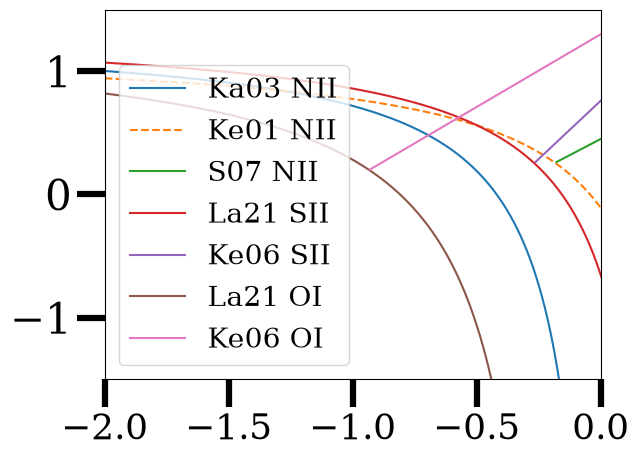

In [15]:
x_plot = np.linspace(-2, 1, 500)

y_b = b(x_plot)
y_c = c(x_plot)

# encontrar donde la diferencia es mínima
idx_c = np.argmin(np.abs(y_b - y_c))
x_int_c = x_plot[idx_c]
mask_c = x_plot > x_int_c

print(x_int_c)

plt.plot(x_kauff, a(x_kauff), '-', label='Ka03 NII')
plt.plot(x_kewley, b(x_kewley), '--', label='Ke01 NII')
plt.plot(x_plot[mask_c], y_c[mask_c], '-', label= 'S07 NII' )

plt.plot(x_s2, d(x_s2), label='La21 SII')
plt.plot(x_plot[mask_e_plot], y_e[mask_e_plot], '-', label='Ke06 SII')

plt.plot(x_o1, f(x_o1), label='La21 OI')
plt.plot(x_plot[mask_g_plot], y_g[mask_g_plot], '-', label='Ke06 OI')

plt.xlim(-2,0)
plt.ylim(-1.5,1.5)

plt.legend()

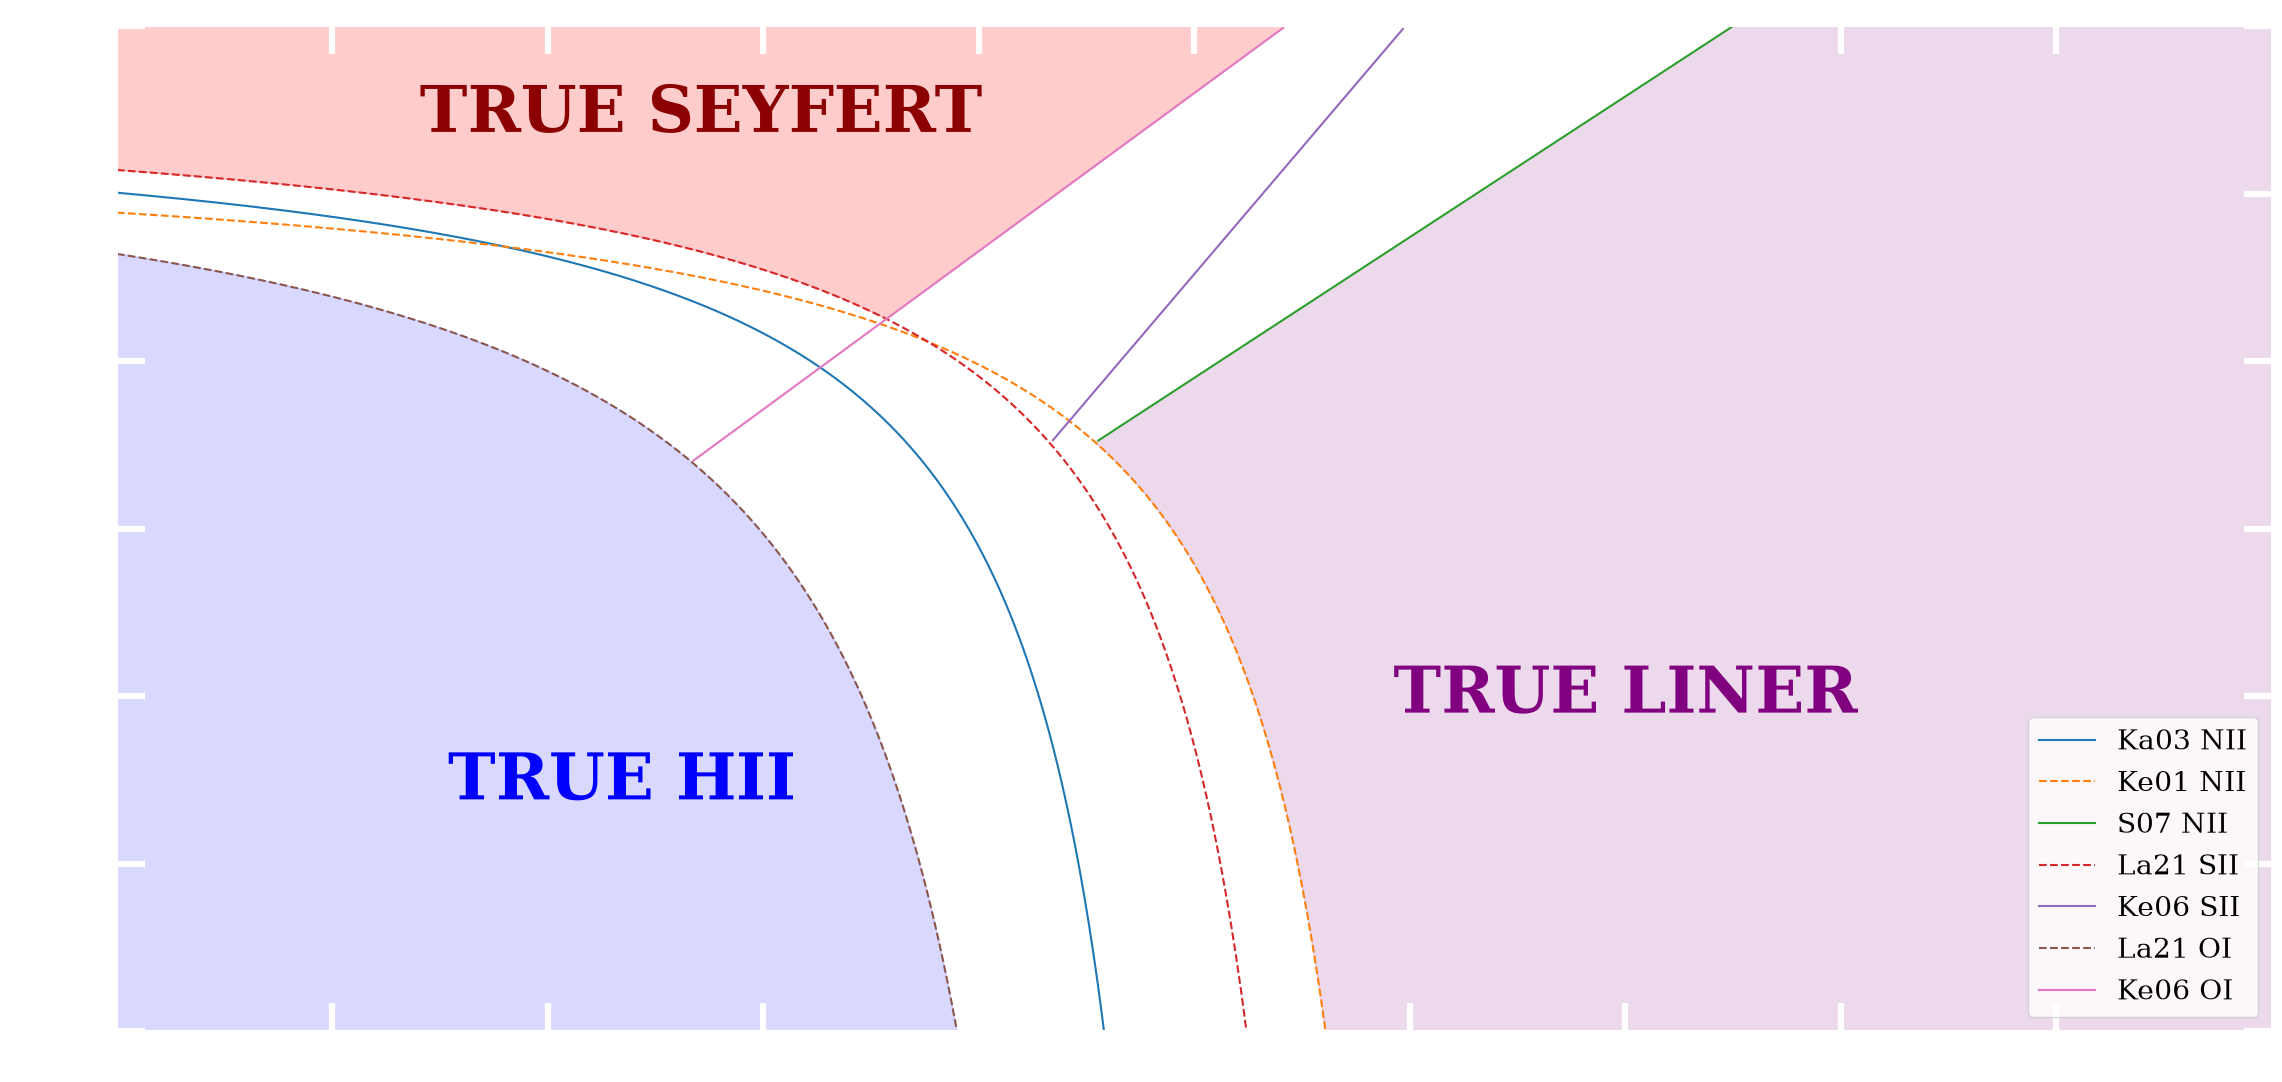

In [16]:
fig, ax = plt.subplots(figsize=(24, 12))

# ============================================================
# CURVAS
# ============================================================
ax.plot(x_kauff, a(x_kauff), '-', label='Ka03 NII')
ax.plot(x_kewley, b(x_kewley), '--', label='Ke01 NII')
ax.plot(x_plot[mask_c], y_c[mask_c], '-', label= 'S07 NII' )

ax.plot(x_s2, d(x_s2),'--', label='La21 SII')
ax.plot(x_plot[mask_e_plot], y_e[mask_e_plot], '-', label='Ke06 SII')

ax.plot(x_o1, f(x_o1),'--', label='La21 OI')
ax.plot(x_plot[mask_g_plot], y_g[mask_g_plot], '-', label='Ke06 OI')

x_region = np.linspace(-2, 2, 2000)


#y_a_r = np.where(x_region < 0.05, a(x_region), -np.inf)
y_b_r = np.where(x_region < 0.324, d(x_region), -np.inf)
y_g_r = g(x_region)

y_floor_s = np.maximum( y_b_r, y_g_r)
y_floor_s = np.clip(y_floor_s, -1.5, 1.5)

valid_s = (y_floor_s < 1.5) & np.isfinite(y_floor_s)
x_s     = x_region[valid_s]
y_s     = y_floor_s[valid_s]

ax.fill(
    np.concatenate([x_s, x_s[::-1]]),
    np.concatenate([y_s, np.full_like(x_s, 1.5)]),
    color='red', alpha=0.20, zorder=0
)
ax.text(np.mean(x_s), (np.mean(y_s) + 1.5) / 2, 'TRUE SEYFERT',
        ha='center', va='center',
        color='darkred', fontweight='bold')


x1    = np.linspace(-2, 0.47, 2000, endpoint=False)
y_b1  = np.clip(b(x1), -1.5, 1.5)
y_c1  = np.clip(c(x1), -1.5, 1.5)
v1    = y_b1 < y_c1
x1_v  = x1[v1];  y_floor1 = y_b1[v1];  y_ceil1 = y_c1[v1]

x2       = np.linspace(0.47, 2, 2000)
y_c2     = np.clip(c(x2), -1.5, 1.5)
y_floor2 = np.full_like(x2, -1.5)

x_l      = np.concatenate([x1_v,    x2      ])
yfl_l    = np.concatenate([y_floor1, y_floor2])
ycu_l    = np.concatenate([y_ceil1,  y_c2   ])

ax.fill(
    np.concatenate([x_l,    x_l[::-1]  ]),
    np.concatenate([ycu_l,  yfl_l[::-1]]),
    color='purple', alpha=0.15, zorder=0
)
ax.text(0.8, -0.5, 'TRUE LINER',
        ha='center', va='center',
        color='purple', fontweight='bold')


x_h   = np.linspace(-2, -0.124, 2000, endpoint=False)
y_f_h = np.clip(f(x_h), -1.5, 1.5)
v_h   = np.isfinite(y_f_h)
x_hv  = x_h[v_h];  y_fv = y_f_h[v_h]

ax.fill(
    np.concatenate([x_hv,  x_hv[::-1]            ]),
    np.concatenate([y_fv,  np.full_like(x_hv,-1.5)]),
    color='blue', alpha=0.15, zorder=0
)
ax.text(np.mean(x_hv), np.mean((y_fv + (-1.5)) / 2), 'TRUE HII',
        ha='center', va='center',
        color='blue', fontweight='bold')


ax.set_xlim(-2, 2)
ax.set_ylim(-1.5, 1.5)
#ax.set_xlabel(r'log([NII]/H$\alpha$) / log([OI]/H$\alpha$)', fontsize=12)
#ax.set_ylabel(r'log([OIII]/H$\beta$)', fontsize=12)
ax.legend(loc='lower right')
ax.tick_params(direction='in', top=True, right=True, color='white', labelcolor='white')
xticks = np.linspace(-2, 2, 11)   # [-2, -1, 0, 1, 2]
ax.set_xticks(xticks[1:-1])       # [-1,  0,  1]
ax.xaxis.label.set_color('white')
ax.yaxis.label.set_color('white')
for spine in ax.spines.values():
    spine.set_color('white')
    spine.set_linewidth(1.5)
plt.tight_layout()
plt.savefig(
    "imagenes/mask_class_desi.png",
    dpi=300,
    transparent=True,
    bbox_inches='tight'
)
plt.show()

<a id="subseccion-2-3"></a>

### 2.3 Selección de clasificador

Segunda parte interactiva del codigo, al igual que la primera parte, fue diseñada asi para realizar distintas pruebas cambiando entre clasificadores, máscaras de los diagramas BPT, rango de redshift y que esto se guarde en 3 .txt separados por clase de galaxia, es decir, un archivo para las Star-foming, otro para las Seyfert y otro para las LINER.

Los resultados son definidos como default:
- Nuestro clasificador
- Todas las mascaras aplicadas
- Redshift en el rango: 0.00-0.05
- Guardar los 3 archivos .txt

In [17]:
def elegir_clasificador(data_myclass, data_desiclass):
    print("\n  Clasificadores disponibles:")
    print("1. data_myclass")
    print("2. data_desiclass")

    while True:
        entrada = input("\n  Elige clasificador [1]: ").strip()
        print("")
        if entrada in ('', '1'):
            print("Usando: data_myclass")
            return data_myclass
        if entrada == '2':
            print("Usando: data_desiclass")
            return data_desiclass
        print("")
        print("Opción no válida, ingresa 1 o 2.")

def elegir_mascaras(data):
    diagramas = ['class_nii', 'class_sii', 'class_oi']
    clases    = ['Seyfert', 'Star-forming', 'LINER']

    print("\n  Selección de diagramas BPT ")

    seleccion = {}  
    for clase in clases:
        activos = []

        for diag in diagramas:
            resp = input(f"¿Usar {diag} en {clase}? [S/n]: ").strip().lower()
            if resp not in ('n', 'no'):
                activos.append(diag)
        if not activos:
            print(f"No seleccionaste ningún diagrama para {clase}, se omite.")
        seleccion[clase] = activos

    print("\n Máscaras aplicadas:")
    for clase, diagramas_activos in seleccion.items():
        if not diagramas_activos:
            print(f"{clase:15s} (ninguna)")
        else:
            condiciones = "  &  ".join([f"{d} == '{clase}'" for d in diagramas_activos])
            print(f"{clase:15s} {condiciones}")
    print("")

    return seleccion

def elegir_redshift():

    while True:
        try:
            z_min = float(input("  Z mínimo [0.00]: ").strip() or 0.00)
            z_max = float(input("  Z máximo [0.05]: ").strip() or 0.05)
            if z_min >= z_max:
                print("Z mínimo debe ser menor que Z máximo.")
                continue
            return z_min, z_max
        except ValueError:
            print("Ingresa un número válido (ej: 0.05).")
    

def aplicar_clasificacion(data, seleccion, z_min, z_max):

    data = data.copy()
    data['final_class'] = ''  

    for clase, diagramas in seleccion.items():
        if not diagramas:
            continue
        mask = pd.Series(True, index=data.index)
        for diag in diagramas:
            mask &= (data[diag] == clase)
        data.loc[mask, 'final_class'] = clase

    mask_z = data['Z'].between(z_min, z_max)
    data_filt = data[mask_z].copy()

    return data_filt

def separar_por_clase(df, col_clasificador):
    classes = ['Star-forming', 'Seyfert', 'LINER']

    cols = [
    'RA',
    'DEC',
    'Z',
    'MJD',
    'h_beta_flux',
    'oiii_5007_flux',
    'oi_6300_flux',
    'h_alpha_flux',
    'nii_6584_flux',
    'sii_6717_flux',
    'sii_6731_flux',
    'mag_auto_r',
    'mag_auto_g',
    'mag_auto_i',
    'mag_auto_z',
    'mag_auto_u',
    'mag_auto_j0378',
    'mag_auto_j0395',
    'mag_auto_j0410',
    'mag_auto_j0430',
    'mag_auto_j0515',
    'mag_auto_j0660',
    'mag_auto_j0861'
    ]

    cols_presentes = [c for c in cols if c in df.columns]
    cols_faltantes = [c for c in cols if c not in df.columns]
    if cols_faltantes:
        print(f"\n Columnas no encontradas: {cols_faltantes}")

    print()
    for c in classes:
        subset = df.loc[df[col_clasificador] == c, cols_presentes]
        nombre = f"{c}.txt"
        subset.to_csv(nombre, sep="\t", index=False)
        print(f"{nombre:20s}: {len(subset):,} galaxias guardadas")


def main():
    print("Clasificador BPT interactivo")

    # 1ero elegir entre clasificadores
    data = elegir_clasificador(data_myclass, data_desiclass)

    # 2do mascaras para Seyferts, star-forming y LINERs
    seleccion = elegir_mascaras(data)

    # 3r elegir rango de redshift
    z_min, z_max = elegir_redshift()

    # 4to aplicar todo
    data_filt = aplicar_clasificacion(data, seleccion, z_min, z_max)

    # 5. Resumen
    print(f"Rango Z aplicado : {z_min} – {z_max}")
    print(f"Galaxias totales : {len(data_filt):,}")
    # 6to Guardar archivos por clase
    otra = input("\n  ¿Guardar .txt por clase? [S/n]: ").strip().lower()
    if otra not in ('n', 'no'):
        separar_por_clase(data_filt, 'final_class')

    print("\nListo.")


if __name__ == '__main__':
    main()

Clasificador BPT interactivo

  Clasificadores disponibles:
1. data_myclass
2. data_desiclass

Usando: data_myclass

  Selección de diagramas BPT 

 Máscaras aplicadas:
Seyfert         class_nii == 'Seyfert'  &  class_sii == 'Seyfert'  &  class_oi == 'Seyfert'
Star-forming    class_nii == 'Star-forming'  &  class_sii == 'Star-forming'  &  class_oi == 'Star-forming'
LINER           class_nii == 'LINER'  &  class_sii == 'LINER'  &  class_oi == 'LINER'

Rango Z aplicado : 0.0 – 0.05
Galaxias totales : 1,834

Star-forming.txt    : 1,364 galaxias guardadas
Seyfert.txt         : 50 galaxias guardadas
LINER.txt           : 60 galaxias guardadas

Listo.


<a id="seccion-3"></a>

## 3. Métodos de machine learning

Acá cargamos los archivos resultantes del codigo interactivo, definimos la cantidad de features los cuales son:

- Redshift
- Magnitudes "mag_auto" de las 12 bandas de SPLUS.

Es importante recalcar que todas las pruebas se realizaron con datos balanceados, es decir, tomando la misma cantidad de galaxias de cada tipo para evitar sesgos en la selección.


In [18]:
plt.rcParams.update({
    "font.size" : 40,   # texto general (celdas, etc.)
    "axes.titlesize" : 55,   # títulos
    "axes.labelsize" : 40,   # labels de ejes x/y
    "xtick.labelsize" : 40,   # tick labels eje x
    "ytick.labelsize" : 40,   # tick labels eje y
})

arquivo_HII=r"C:\Users\amand\Desktop\tesis_ama\codes\final_results\Star-forming.txt"
arquivo_Seyfert=r"C:\Users\amand\Desktop\tesis_ama\codes\final_results\Seyfert.txt"
arquivo_LINER=r"C:\Users\amand\Desktop\tesis_ama\codes\final_results\LINER.txt"

galaxias_HII=np.genfromtxt(arquivo_HII, dtype=float, delimiter="\t", skip_header=1)
z_HII=galaxias_HII.shape
galaxias_Seyfert=np.genfromtxt(arquivo_Seyfert,dtype=float, delimiter="\t", skip_header=1)
z_Seyfert=galaxias_Seyfert.shape
galaxias_LINER=np.genfromtxt(arquivo_LINER,dtype=float, delimiter="\t", skip_header=1)
z_LINER=galaxias_LINER.shape

print("HII:", galaxias_HII.shape)
print("Seyfert:",galaxias_Seyfert.shape)
print("LINER:",galaxias_LINER.shape)

N = min( galaxias_HII.shape[0],galaxias_Seyfert.shape[0],galaxias_LINER.shape[0])

X=np.zeros((3*N,12))
Y=np.zeros(3*N)

#X[0:N, 0] = galaxias_HII[0:N, 2]
X[0:N, 0:12] = galaxias_HII[0:N, 11:23]

#X[N:2 * N, 0] = galaxias_Seyfert[0:N, 2]
X[N:2 * N,0:12] = galaxias_Seyfert[0:N, 11:23]

#X[2 * N:3 * N, 0] = galaxias_LINER[0:N, 2]
X[2 * N:3 * N, 0:12] = galaxias_LINER[0:N, 11:23]

for w in range(0,N):
    Y[w]=0
    
for w in range(N,2*N):
    Y[w]=1

for w in range(2*N,3*N):
    Y[w]=2

#Normalizing the data
scaler = preprocessing.StandardScaler()
X = scaler.fit_transform(X)
joblib.dump(scaler, "scaler.pkl")


seed = 7
test_size = 0.2

clase_map = {'HII': 0.0, 'Seyfert': 1.0, 'LINER': 2.0}
clase_map_inverso = {v: k for k, v in clase_map.items()}

joblib.dump(clase_map, "clase_map.pkl")
joblib.dump(clase_map_inverso,"clase_map_inverso.pkl")

HII: (1364, 23)
Seyfert: (50, 23)
LINER: (60, 23)


['clase_map_inverso.pkl']

<a id="seccion-3-1"></a>

### 3.1 Decision Tree balanced

Best max_depth: 2
Final Accuracy: 56.67


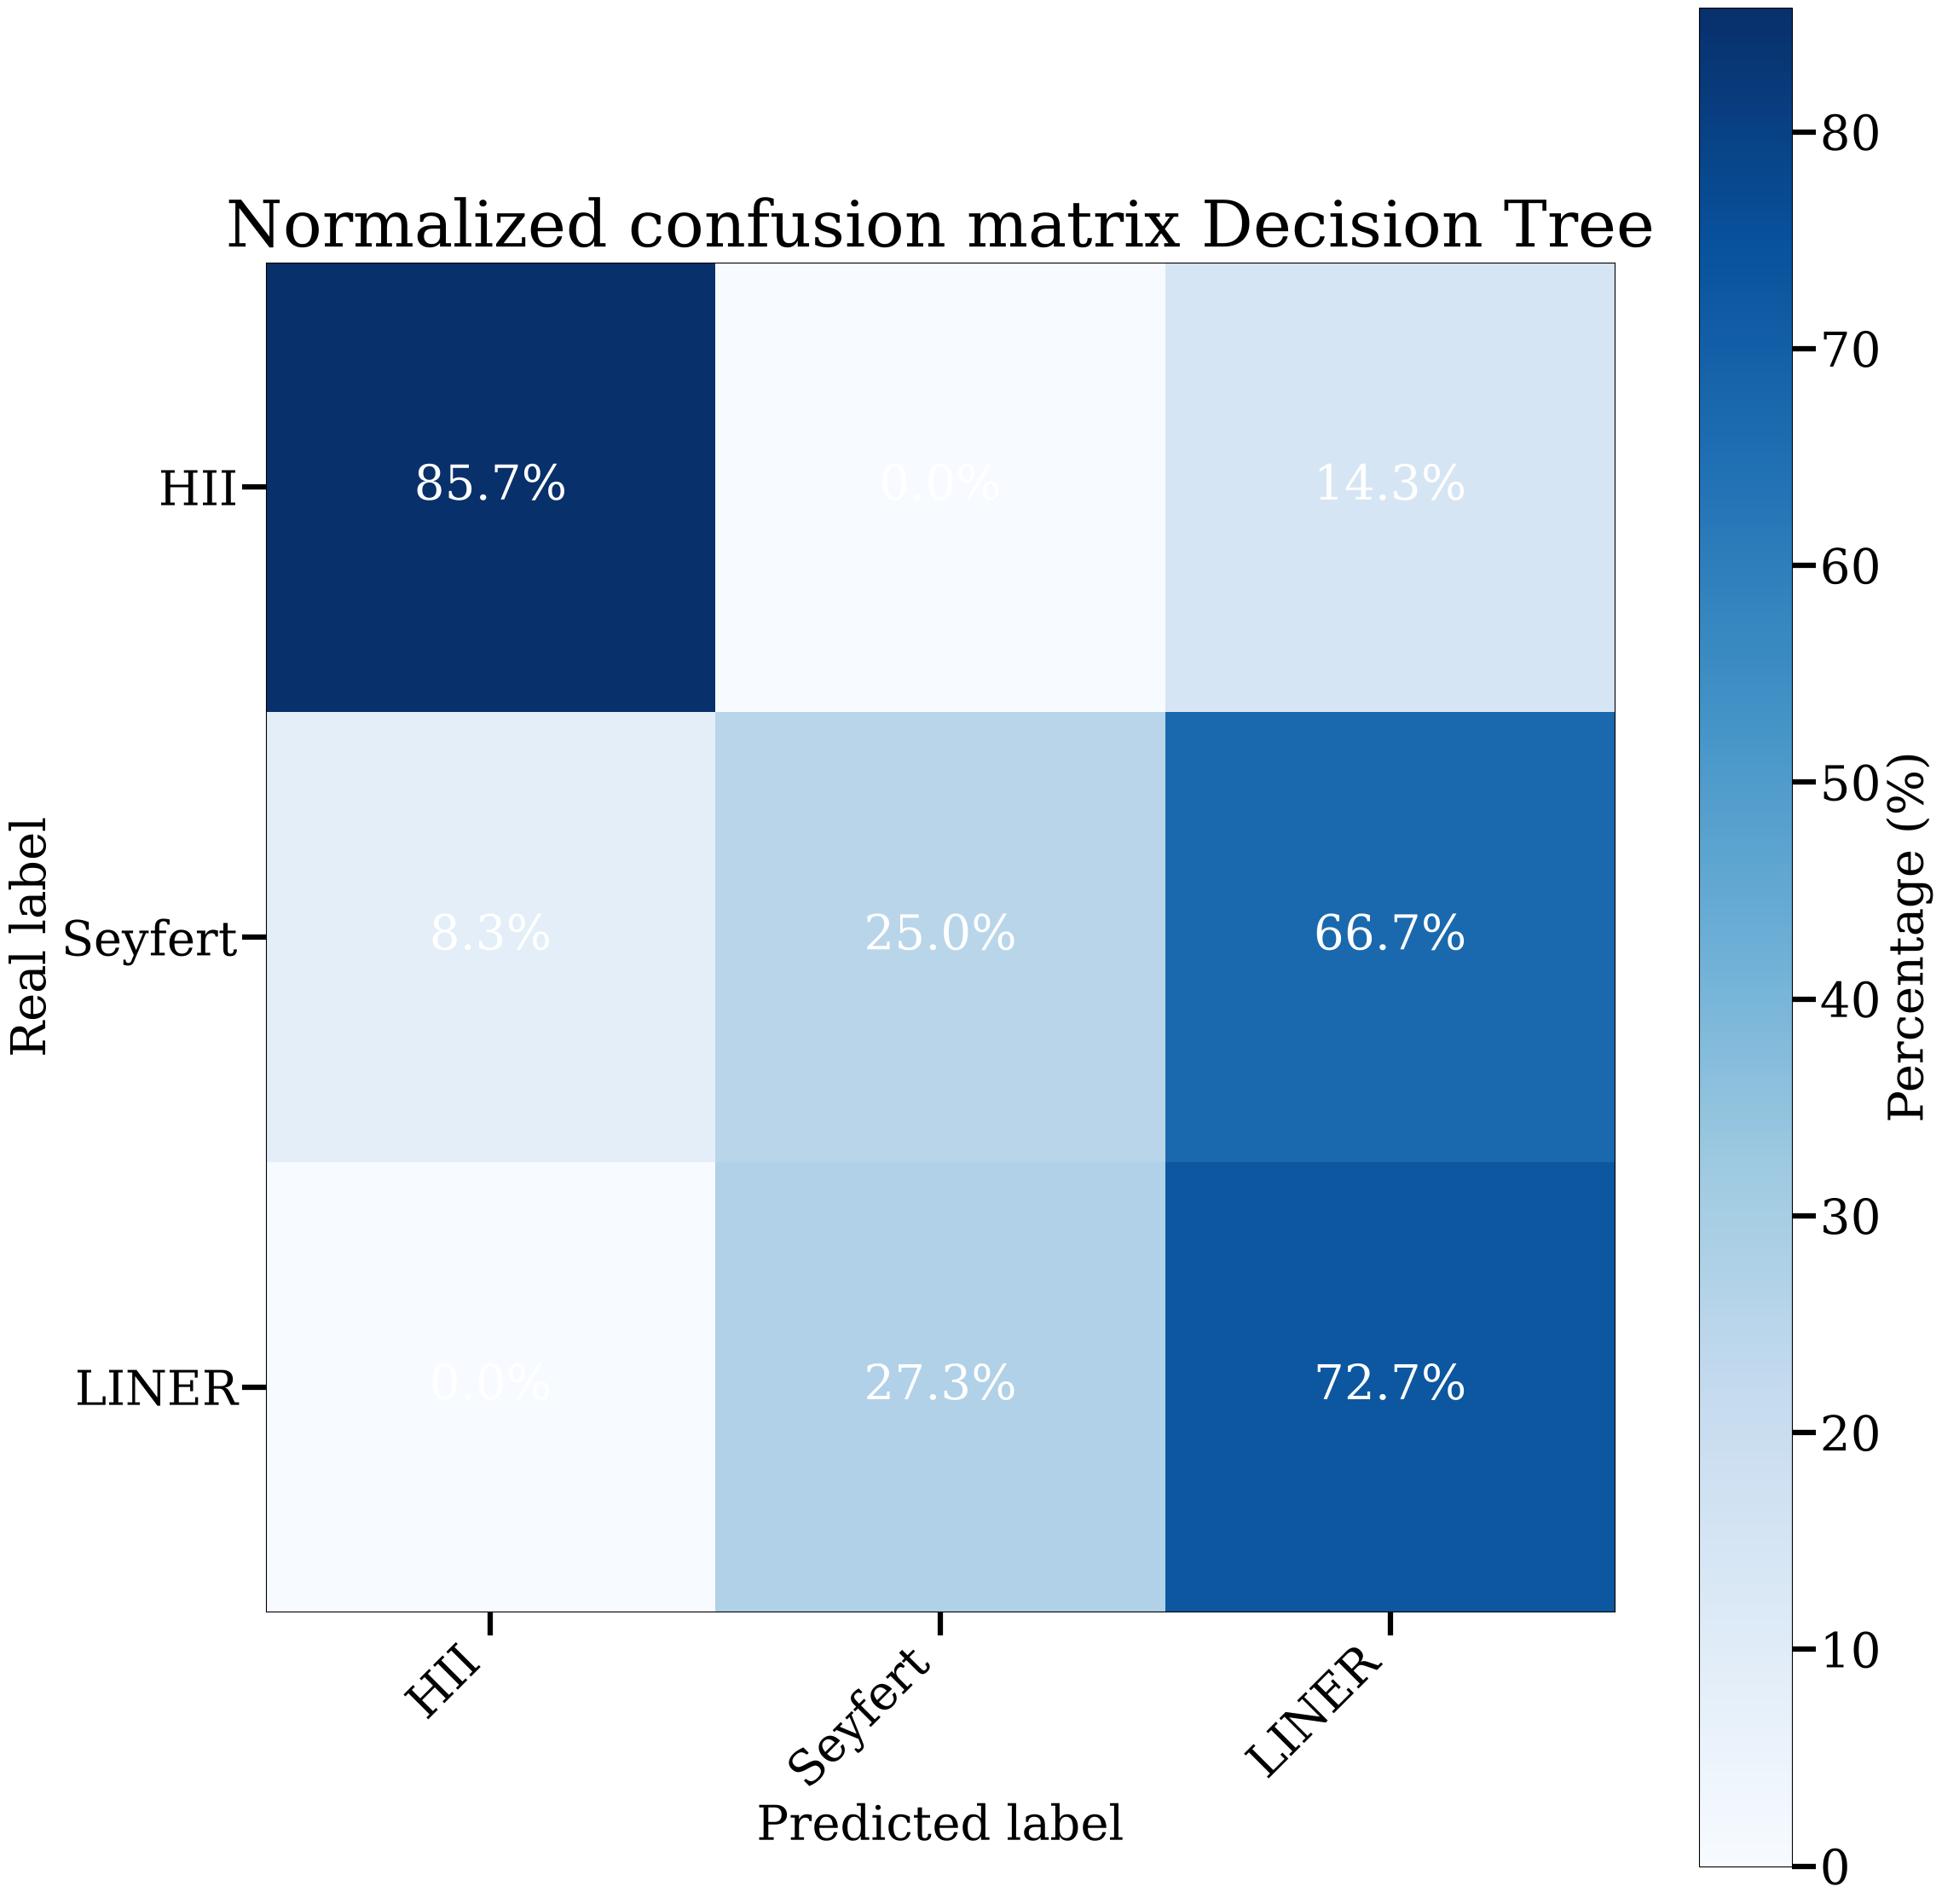

float64
{np.float64(0.0), np.float64(1.0), np.float64(2.0)}


In [19]:
#DT
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=test_size, random_state=seed)   

ks = range(1, 21)
accuracies = []

for k in ks:
    model = DecisionTreeClassifier(max_depth=k, random_state=seed)
    scores = cross_val_score(model, X_train, Y_train, cv=5)
    accuracies.append(scores.mean())
    
kbest = np.argmax(accuracies) + 1
print("Best max_depth:", kbest)
        

#Final model
model = DecisionTreeClassifier(max_depth=kbest, random_state=seed)
model.fit(X_train, Y_train)
Y_pred = model.predict(X_test)

print("Final Accuracy: {:.2f}".format(accuracy_score(Y_test, Y_pred)*100))


#Building the confusion matrix
classes = ["HII", "Seyfert", "LINER"]

cm = confusion_matrix(
    Y_test,
    Y_pred,
    labels=[0, 1, 2] 
)

cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
cm_norm = np.nan_to_num(cm_norm)

fig, ax = plt.subplots(figsize=(24, 24))
im = ax.imshow(cm_norm, cmap="Blues")

for i in range(cm_norm.shape[0]):
    for j in range(cm_norm.shape[1]):
        ax.text(
            j, i,
            f"{cm_norm[i, j]:.1f}%",
            ha="center",
            va="center",
            color="white",
            fontsize=40
        )

ax.set_xticks(range(3))
ax.set_yticks(range(3))
ax.set_xticklabels(classes, rotation=45, ha="right",fontsize=40)
ax.set_yticklabels(classes, fontsize=40)

ax.set_xlabel("Predicted label",fontsize=40)
ax.set_ylabel("Real label",fontsize=40)
ax.set_title("Normalized confusion matrix Decision Tree", fontsize=55)

# Barra de cores
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Percentage (%)",fontsize=40)
cbar.ax.tick_params(labelsize=40)

c = 'black'


plt.tight_layout()
# plt.savefig(
#     "imagenes/DT_DESI.png",
#     dpi=150,
#     transparent=True,
#     bbox_inches='tight'
# )

plt.show()

joblib.dump(model, "modelo_dt.pkl")
Y_pred_DT   = model.predict(X_test)             
Y_test_DT   = Y_test.copy()

print(Y_train.dtype)
print(Y_train.unique() if hasattr(Y_train, 'unique') else set(Y_train))


<a id="seccion-3-2"></a>

### 3.2 Deep Neural Network balanced

Epoch 1/50


c:\Users\amand\Desktop\tesis_ama\codes\agn\gal.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.4167 - loss: 1.0188 - val_accuracy: 0.6000 - val_loss: 0.8683
Epoch 2/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5417 - loss: 0.8902 - val_accuracy: 0.6000 - val_loss: 0.8145
Epoch 3/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5583 - loss: 0.8565 - val_accuracy: 0.6333 - val_loss: 0.7846
Epoch 4/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5667 - loss: 0.8216 - val_accuracy: 0.6667 - val_loss: 0.8077
Epoch 5/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6250 - loss: 0.7873 - val_accuracy: 0.6333 - val_loss: 0.8640
Epoch 6/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6500 - loss: 0.7650 - val_accuracy: 0.5333 - val_loss: 0.8801
Epoch 7/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6250 - loss: 0.7426 - val_accuracy: 0.7000 - val_loss: 0.8626
Epoch 8/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6417 - loss: 0.7155 - val_accuracy: 0.5667 - val_loss: 0.9799
Epoch 9/50


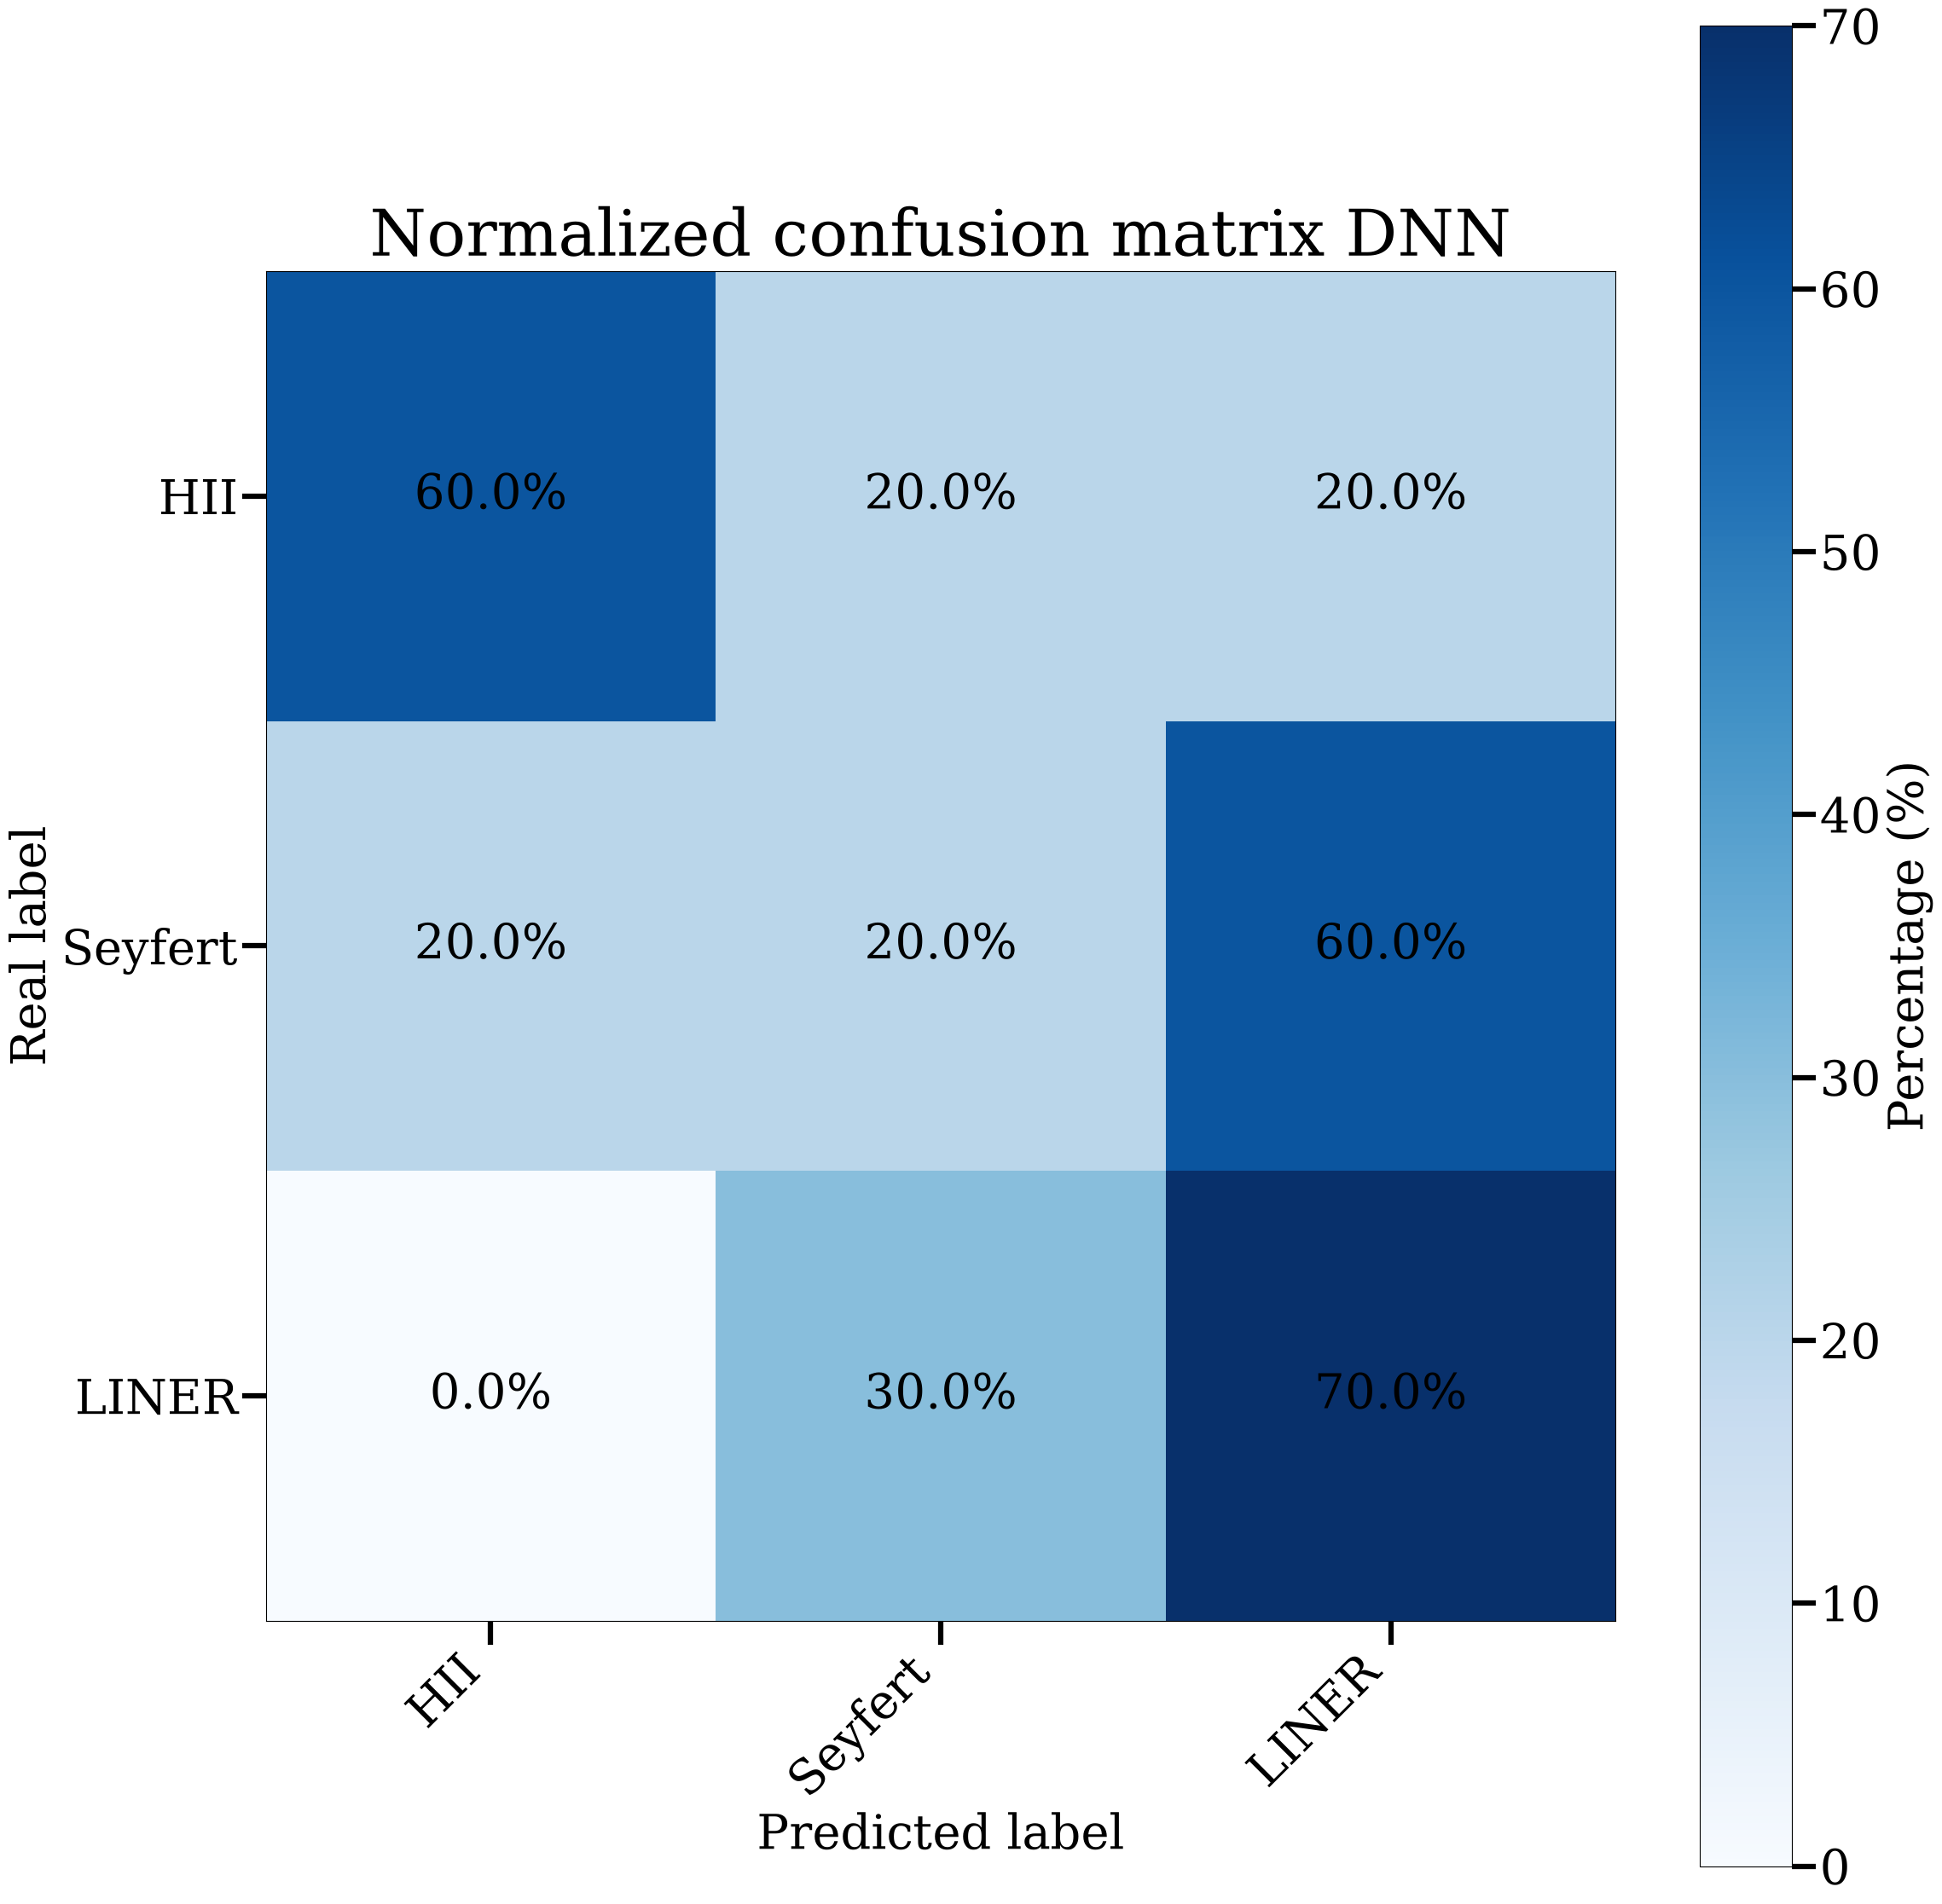

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


In [20]:
#DNN
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=test_size, random_state=seed, stratify=Y
)

model = Sequential()

#First layer with 512 neurons
model.add(Dense(512, activation='relu', input_shape=(X_train.shape[1],)))

#Second layer with 256 neurons
model.add(Dense(256, activation='relu'))

#Third layer with 128 neurons
model.add(Dense(128, activation='relu'))

#Output layer with 3 neurons (one for each class of objects)
model.add(Dense(3, activation='softmax'))


#Final model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

model.fit(X_train, Y_train, epochs=50, batch_size=32, validation_data=(X_test, Y_test))

test_loss, test_acc = model.evaluate(X_test, Y_test)

Y_pred = np.argmax(model.predict(X_test), axis=1)

#Accuracy of the model in the test sample
print(f"Final accuracy: {accuracy_score(Y_test, Y_pred)*100:.2f}")


#Building the confusion matrix
cm = confusion_matrix(Y_test, Y_pred, labels=[0, 1, 2])

cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
cm_norm = np.nan_to_num(cm_norm)

classes = ["HII", "Seyfert", "LINER"]
fig, ax = plt.subplots(figsize=(24,24))
im = ax.imshow(cm_norm, cmap="Blues")

for i in range(cm_norm.shape[0]):
    for j in range(cm_norm.shape[1]):
        ax.text(j, i, f"{cm_norm[i, j]:.1f}%", ha="center", va="center", color="black")

ax.set_xticks(range(3))
ax.set_yticks(range(3))
ax.set_xticklabels(classes, rotation=45, ha="right", color="black")
ax.set_yticklabels(classes, color="black")
ax.set_xlabel("Predicted label", color="black")
ax.set_ylabel("Real label", color="black")
ax.set_title("Normalized confusion matrix DNN", color='black')
ax.tick_params(colors="black")
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Percentage (%)", color="black")
cbar.ax.tick_params(colors="black")
cbar.ax.yaxis.set_tick_params(color="black")
cbar.ax.yaxis.label.set_color("black")

plt.savefig(
    "imagenes/DNN_b.png",
    dpi=300,
    transparent=False,
    bbox_inches='tight'
)

plt.tight_layout()
plt.show()

model.save("modelo_dnn.keras")
Y_pred_DNN  = np.argmax(model.predict(X_test), axis=1)
proba_DNN   = model.predict(X_test)              
Y_test_DNN  = Y_test.copy()

<a id="seccion-3-3"></a>

### 3.3 Random Forest balanced

Best n_estimators: 48
Best max_depth: 9
Best min_samples_leaf: 2
Final Accuracy: 60.00


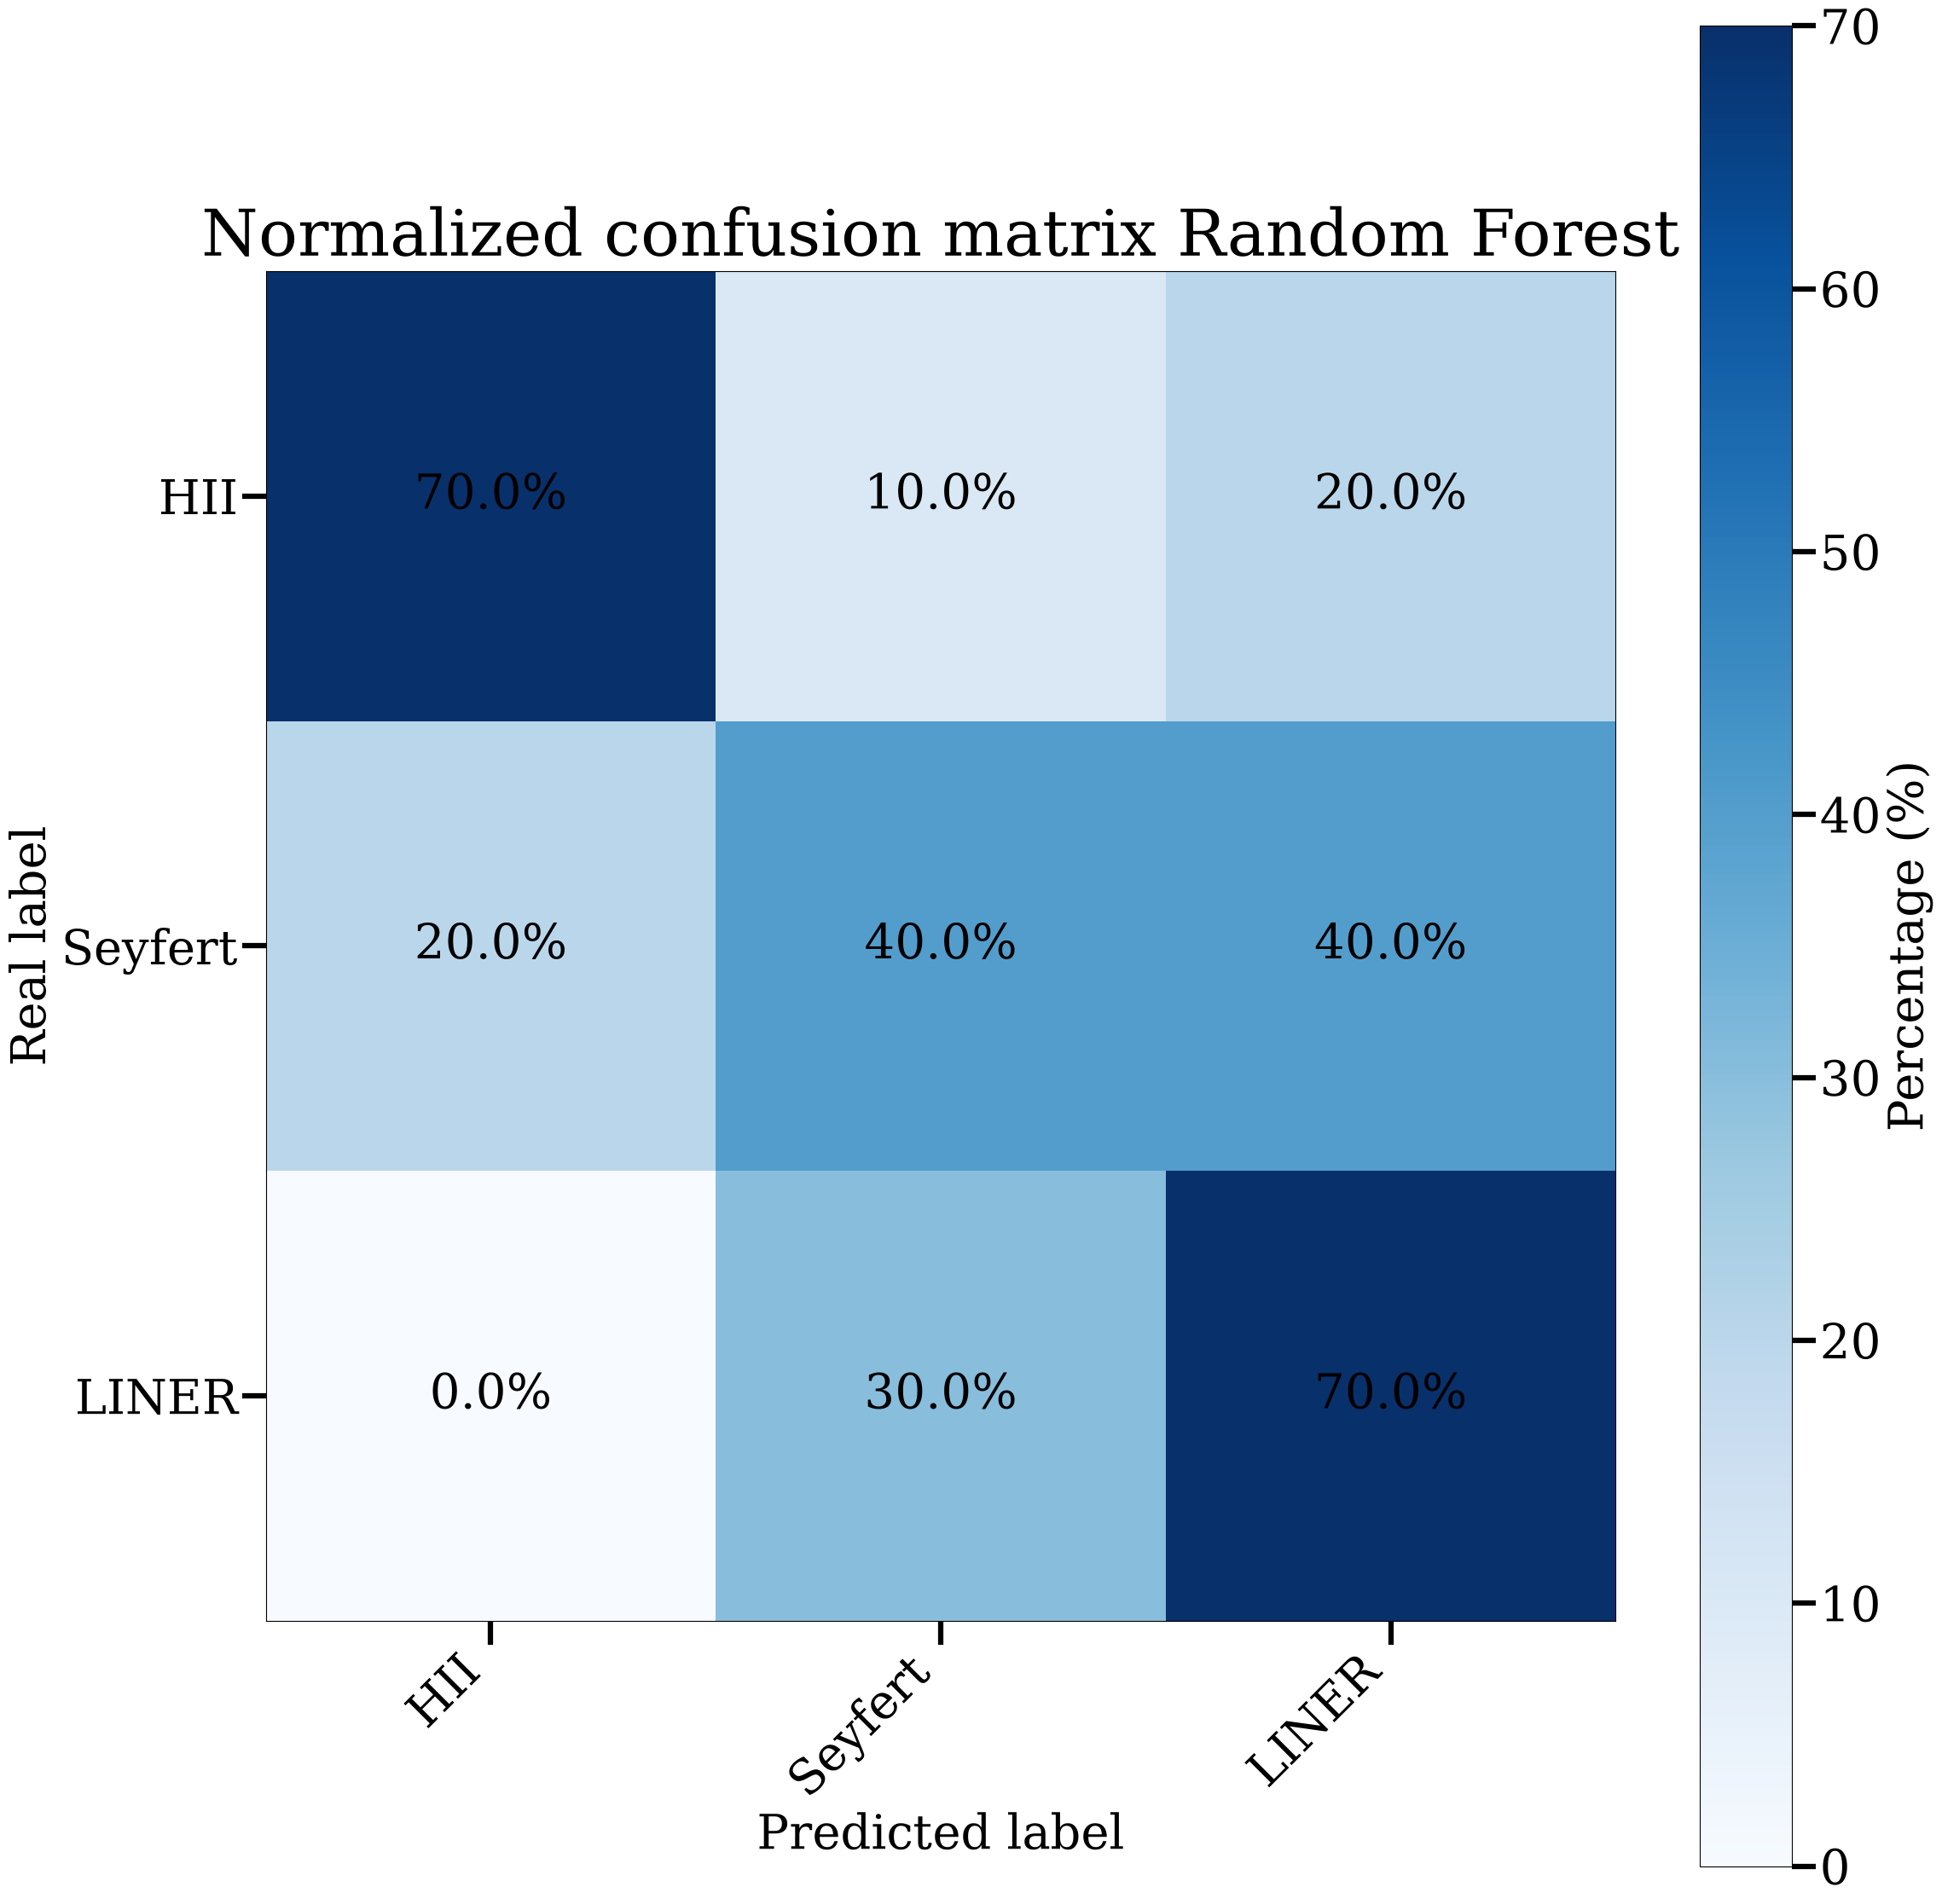

In [21]:
#RF
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=test_size, random_state=seed, stratify=Y
)


#Determining the best value for "n_estimators"
accuracies = []
for n in range(1, 101):
    model = RandomForestClassifier(n_estimators=n, random_state=seed)
    scores = cross_val_score(model, X_train, Y_train, cv=5)
    accuracies.append(scores.mean())
n_best = np.argmax(accuracies) + 1
print("Best n_estimators:", n_best)

#Determining the best value for "max_depth"
accuracies = []
for d in range(1, 21):
    model = RandomForestClassifier(n_estimators=n_best, max_depth=d, random_state=seed)
    scores = cross_val_score(model, X_train, Y_train, cv=5)
    accuracies.append(scores.mean())
d_best = np.argmax(accuracies) + 1
print("Best max_depth:", d_best)

#Determining the best value for "min_samples_leaf"
accuracies = []
for m in range(1, 11):
    model = RandomForestClassifier(
        n_estimators=n_best, max_depth=d_best, min_samples_leaf=m, random_state=seed)
    scores = cross_val_score(model, X_train, Y_train, cv=5)
    accuracies.append(scores.mean())
m_best = np.argmax(accuracies) + 1
print("Best min_samples_leaf:", m_best)


#Final model
final_model = RandomForestClassifier(
    n_estimators=n_best,
    max_depth=d_best,
    min_samples_leaf=m_best,
    random_state=seed
)
final_model.fit(X_train, Y_train)
Y_pred = final_model.predict(X_test)

print("Final Accuracy: {:.2f}".format(accuracy_score(Y_test, Y_pred)*100))


#Building the confusion matrix
classes = ["HII", "Seyfert", "LINER"]
cm = confusion_matrix(Y_test, Y_pred, labels=[0,1,2])
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
cm_norm = np.nan_to_num(cm_norm)

fig, ax = plt.subplots(figsize=(24,24))
im = ax.imshow(cm_norm, cmap="Blues")

for i in range(cm_norm.shape[0]):
    for j in range(cm_norm.shape[1]):
        ax.text(j, i, f"{cm_norm[i,j]:.1f}%", ha="center", va="center", color="black",fontsize=40)

ax.set_xticks(range(3))
ax.set_yticks(range(3))
ax.set_xticklabels(classes, rotation=45, ha="right",fontsize=40)
ax.set_yticklabels(classes,fontsize=40)
ax.set_xlabel("Predicted label", fontsize=40)
ax.set_ylabel("Real label",fontsize=40)
ax.set_title("Normalized confusion matrix Random Forest",fontsize=55)
cbar = fig.colorbar(im, ax=ax)
cbar.ax.tick_params(labelsize=40)
cbar.set_label("Percentage (%)", fontsize=40)

plt.tight_layout()

# plt.savefig(
#     "imagenes/RF_DESI.png",
#     dpi=150,
#     transparent=True,
#     bbox_inches='tight'
# )

plt.show()

joblib.dump(final_model, "modelo_rf.pkl")
Y_pred_RF   = final_model.predict(X_test)       
proba_RF    = final_model.predict_proba(X_test)
Y_test_RF   = Y_test.copy()

<a id="seccion-3-4"></a>

### 3.4 Xgboost balanced

Best n_estimators: 1
Best max_depth: 1
Best learning_rate: 0.5
Final Accuracy: 63.33


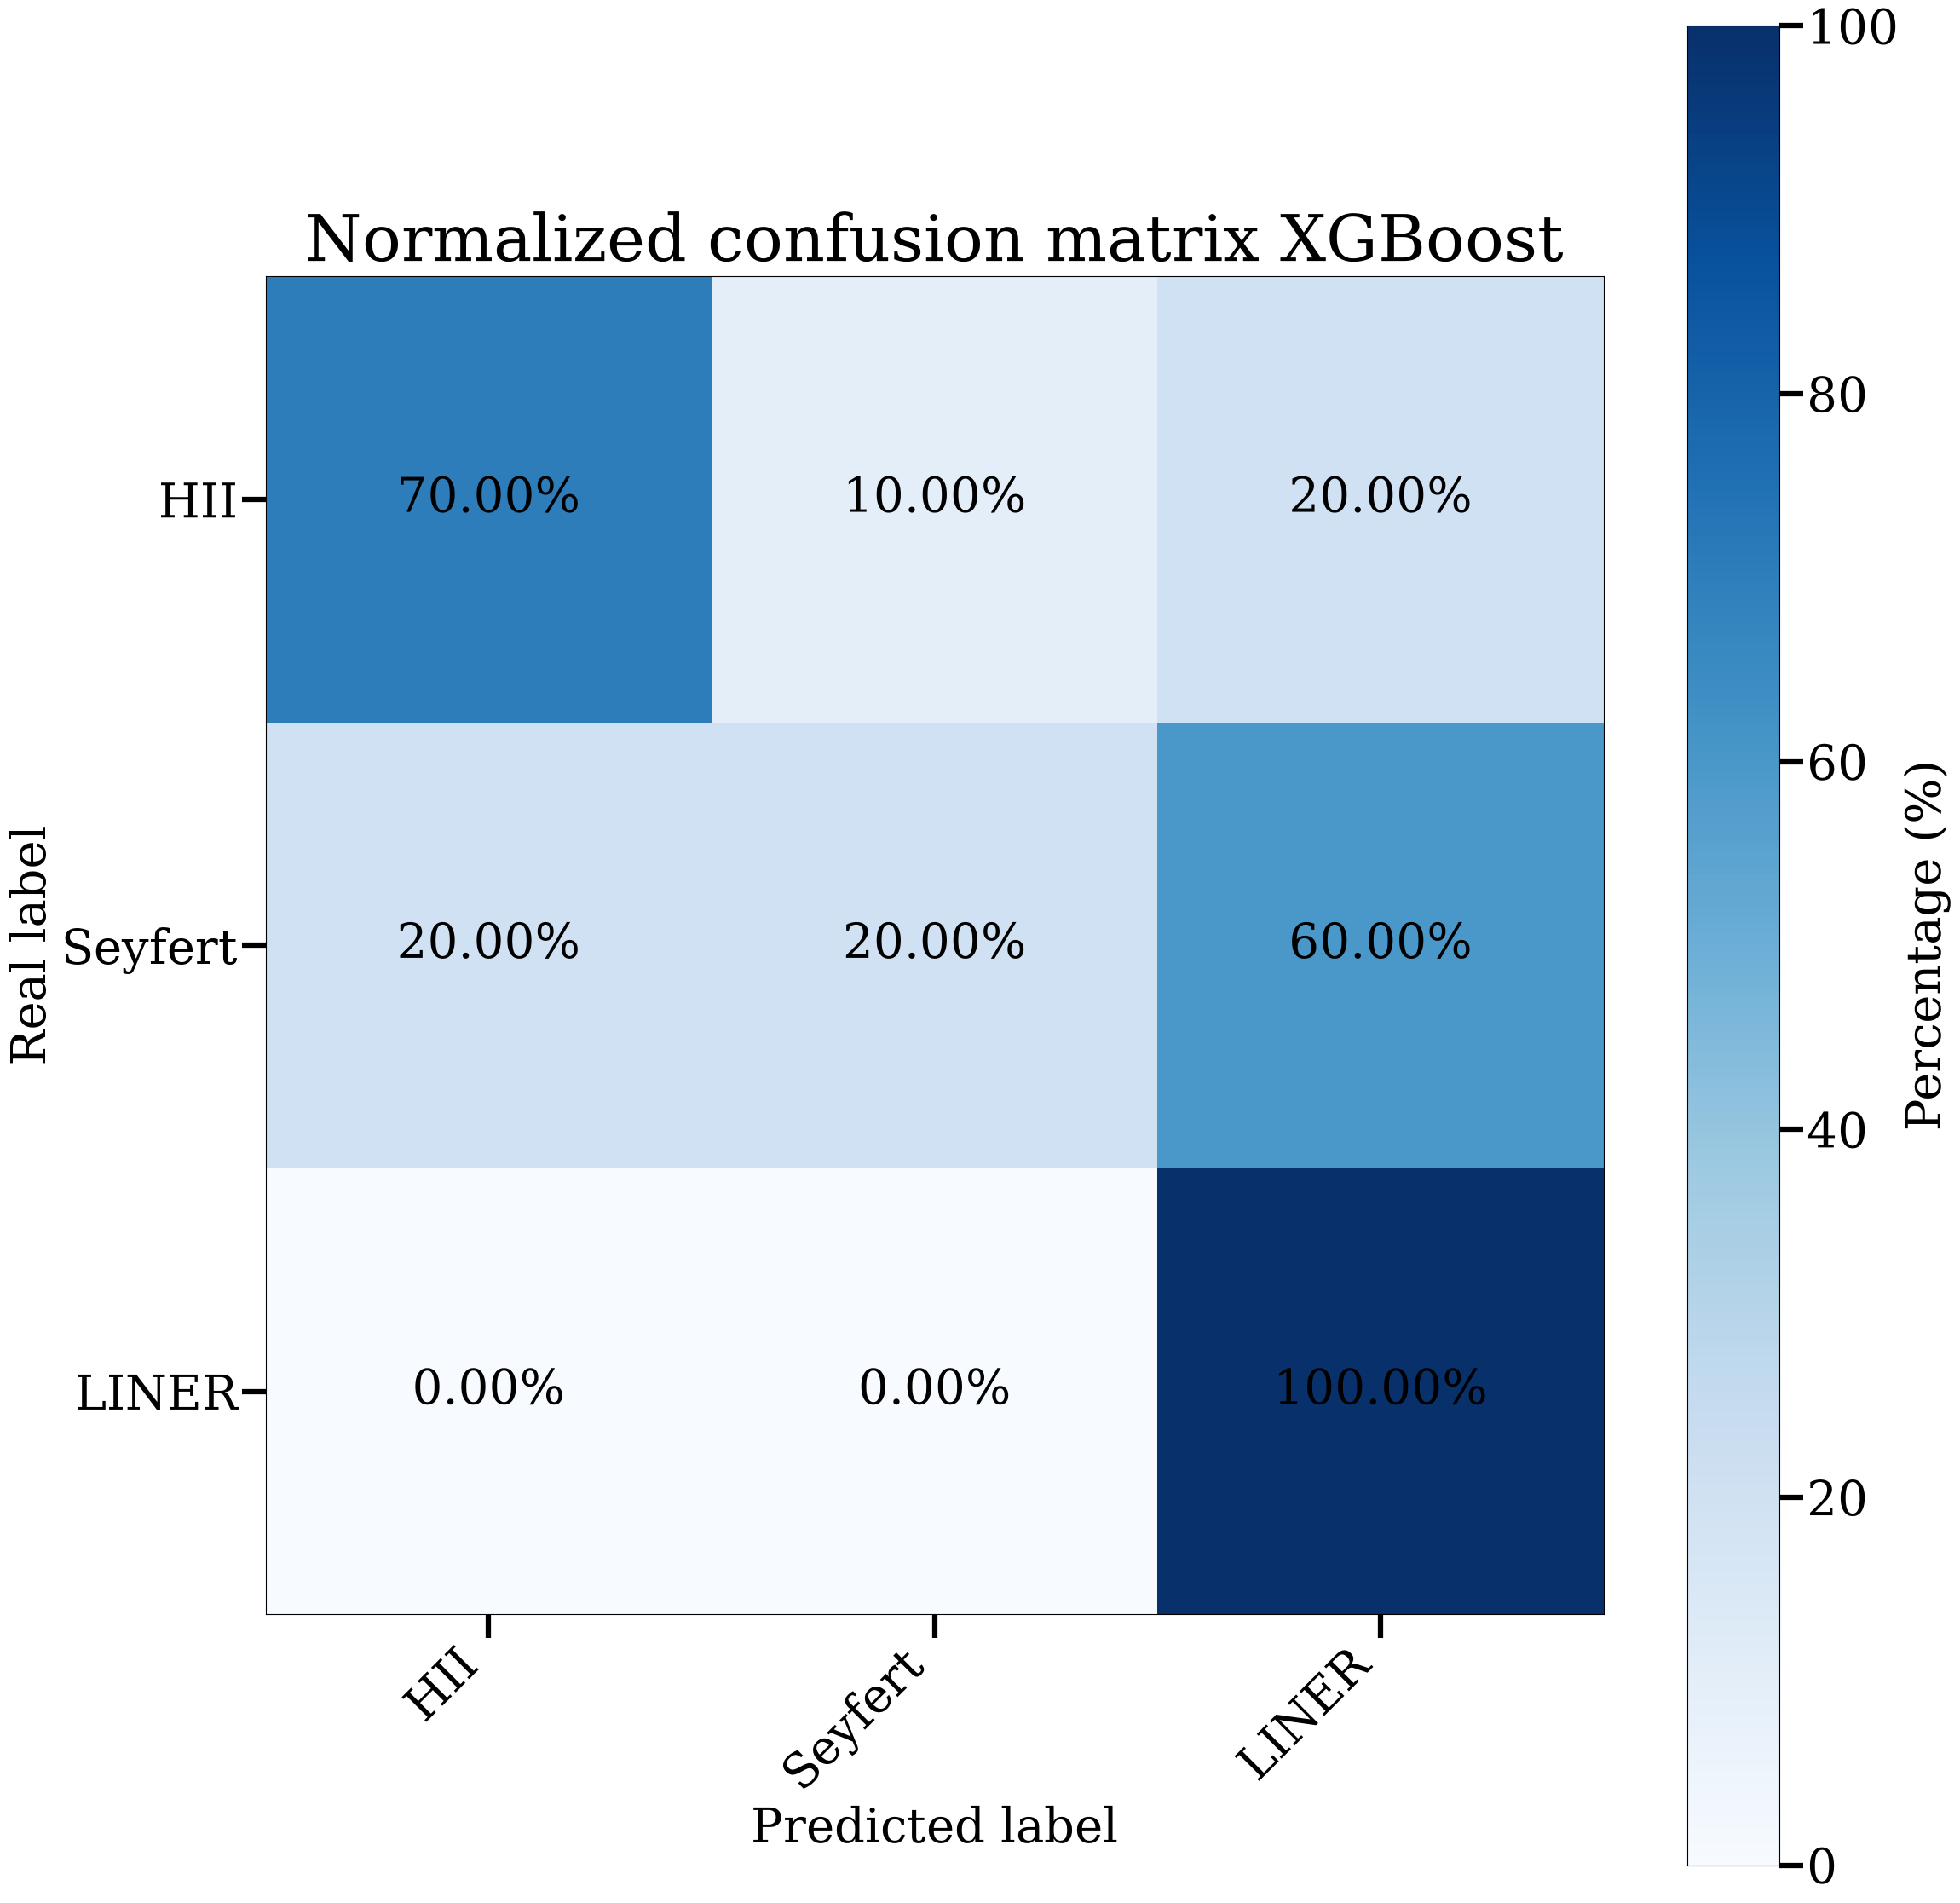

In [22]:
#XgBoost
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=test_size, random_state=seed, stratify=Y
)

#Determining the best value for "n_estimators"
accuracies = []
for n in range(1, 101):
    model = XGBClassifier(n_estimators=n, random_state=seed)
    scores = cross_val_score(model, X_train, Y_train, cv=5)
    accuracies.append(scores.mean())
n_best = np.argmax(accuracies) + 1
print("Best n_estimators:", n_best)


#Determining the best value for "max_depth"
accuracies = []
for d in range(1, 11):
    model = XGBClassifier(n_estimators=n_best, max_depth=d, random_state=seed)
    scores = cross_val_score(model, X_train, Y_train, cv=5)
    accuracies.append(scores.mean())
d_best = np.argmax(accuracies) + 1
print("Best max_depth:", d_best)


#Determining the best value for "learning_rate"
ls = np.arange(0.01, 0.51, 0.01)
accuracies=np.zeros(50)

w=1
for l in ls:
    model = XGBClassifier(n_estimators=n_best, max_depth=d_best, learning_rate=l,random_state=seed)
    model.fit(X_train, Y_train)
    Y_pred = model.predict(X_test)
    predictions = [round(value) for value in Y_pred]
    accuracies[w-1]=accuracy_score(Y_test, predictions)
    w=w+1
    
accuracy=max(accuracies)

w=1
for l in ls:
    if (accuracies[w-1] == accuracy):
        l_best=l
    w=w+1
    
print("Best learning_rate:", l_best)


#Final model
final_model = XGBClassifier(
    n_estimators=n_best,
    max_depth=d_best,
    learning_rate=l_best,
    random_state=seed
)
final_model.fit(X_train, Y_train)
Y_pred = final_model.predict(X_test)

print("Final Accuracy: {:.2f}".format(accuracy_score(Y_test, Y_pred)*100))


#Building the confusion matrix
classes = ["HII", "Seyfert", "LINER"]
cm = confusion_matrix(Y_test, Y_pred, labels=[0,1,2])
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
cm_norm = np.nan_to_num(cm_norm)

fig, ax = plt.subplots(figsize=(24,24))
im = ax.imshow(cm_norm, cmap="Blues")

for i in range(cm_norm.shape[0]):
    for j in range(cm_norm.shape[1]):
        ax.text(j, i, f"{cm_norm[i,j]:.2f}%", ha="center", va="center", color="black")

ax.set_xticks(range(3))
ax.set_yticks(range(3))
ax.set_xticklabels(classes, rotation=45, ha="right")
ax.set_yticklabels(classes)
ax.set_xlabel("Predicted label")
ax.set_ylabel("Real label")
ax.set_title("Normalized confusion matrix XGBoost")
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Percentage (%)")



# plt.savefig(
#     "imagenes/Xgboost_DESI.png",
#     dpi=150,
#     transparent=True,
#     bbox_inches='tight'
# )

plt.tight_layout()
plt.show()

joblib.dump(final_model, "modelo_xgb.pkl")

Y_pred_XGB  = final_model.predict(X_test)       
proba_XGB   = final_model.predict_proba(X_test)
Y_test_XGB  = Y_test.copy()

In [23]:

CLASS_NAMES  = ["HII", "Seyfert", "LINER"]
CLASS_COLORS = {"HII": "#0B1460FF", "Seyfert": "#E81414FF", "LINER": "#9D0386FF"}

def sens_spec(y_true, y_pred, class_names=CLASS_NAMES):

    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    cm     = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
    rows   = []

    for k in range(len(class_names)):
        TP = cm[k, k]
        FN = cm[k, :].sum() - TP
        FP = cm[:, k].sum() - TP
        TN = cm.sum() - TP - FN - FP

        rows.append({
            "Class"      : class_names[k],
            "TP"         : int(TP),
            "FN"         : int(FN),
            "FP"         : int(FP),
            "TN"         : int(TN),
            "Sensitivity": round(TP / (TP + FN), 4) if (TP + FN) > 0 else 0.0,
            "Specificity": round(TN / (TN + FP), 4) if (TN + FP) > 0 else 0.0,
        })

    return pd.DataFrame(rows)

In [24]:
resultados = {}

for nombre, y_true, y_pred in [
    ("Decision Tree", Y_test_DT,  Y_pred_DT),
    ("DNN", Y_test_DNN, Y_pred_DNN),
    ("Random Forest", Y_test_RF,  Y_pred_RF),
    ("XGBoost", Y_test_XGB, Y_pred_XGB),
]:
    df = sens_spec(y_true, y_pred)
    df.insert(0, "Model", nombre)
    resultados[nombre] = df

df_resumen = pd.concat(resultados.values(), ignore_index=True)

print("=" * 68)
print("  Sensitivity & Specificity — todos los modelos")
print("=" * 68)
print(df_resumen.to_string(index=False))
print("=" * 68)

  Sensitivity & Specificity — todos los modelos
        Model   Class  TP  FN  FP  TN  Sensitivity  Specificity
Decision Tree     HII   6   1   1  22       0.8571       0.9565
Decision Tree Seyfert   3   9   3  15       0.2500       0.8333
Decision Tree   LINER   8   3   9  10       0.7273       0.5263
          DNN     HII   6   4   2  18       0.6000       0.9000
          DNN Seyfert   2   8   5  15       0.2000       0.7500
          DNN   LINER   7   3   8  12       0.7000       0.6000
Random Forest     HII   7   3   2  18       0.7000       0.9000
Random Forest Seyfert   4   6   4  16       0.4000       0.8000
Random Forest   LINER   7   3   6  14       0.7000       0.7000
      XGBoost     HII   7   3   2  18       0.7000       0.9000
      XGBoost Seyfert   2   8   1  19       0.2000       0.9500
      XGBoost   LINER  10   0   8  12       1.0000       0.6000


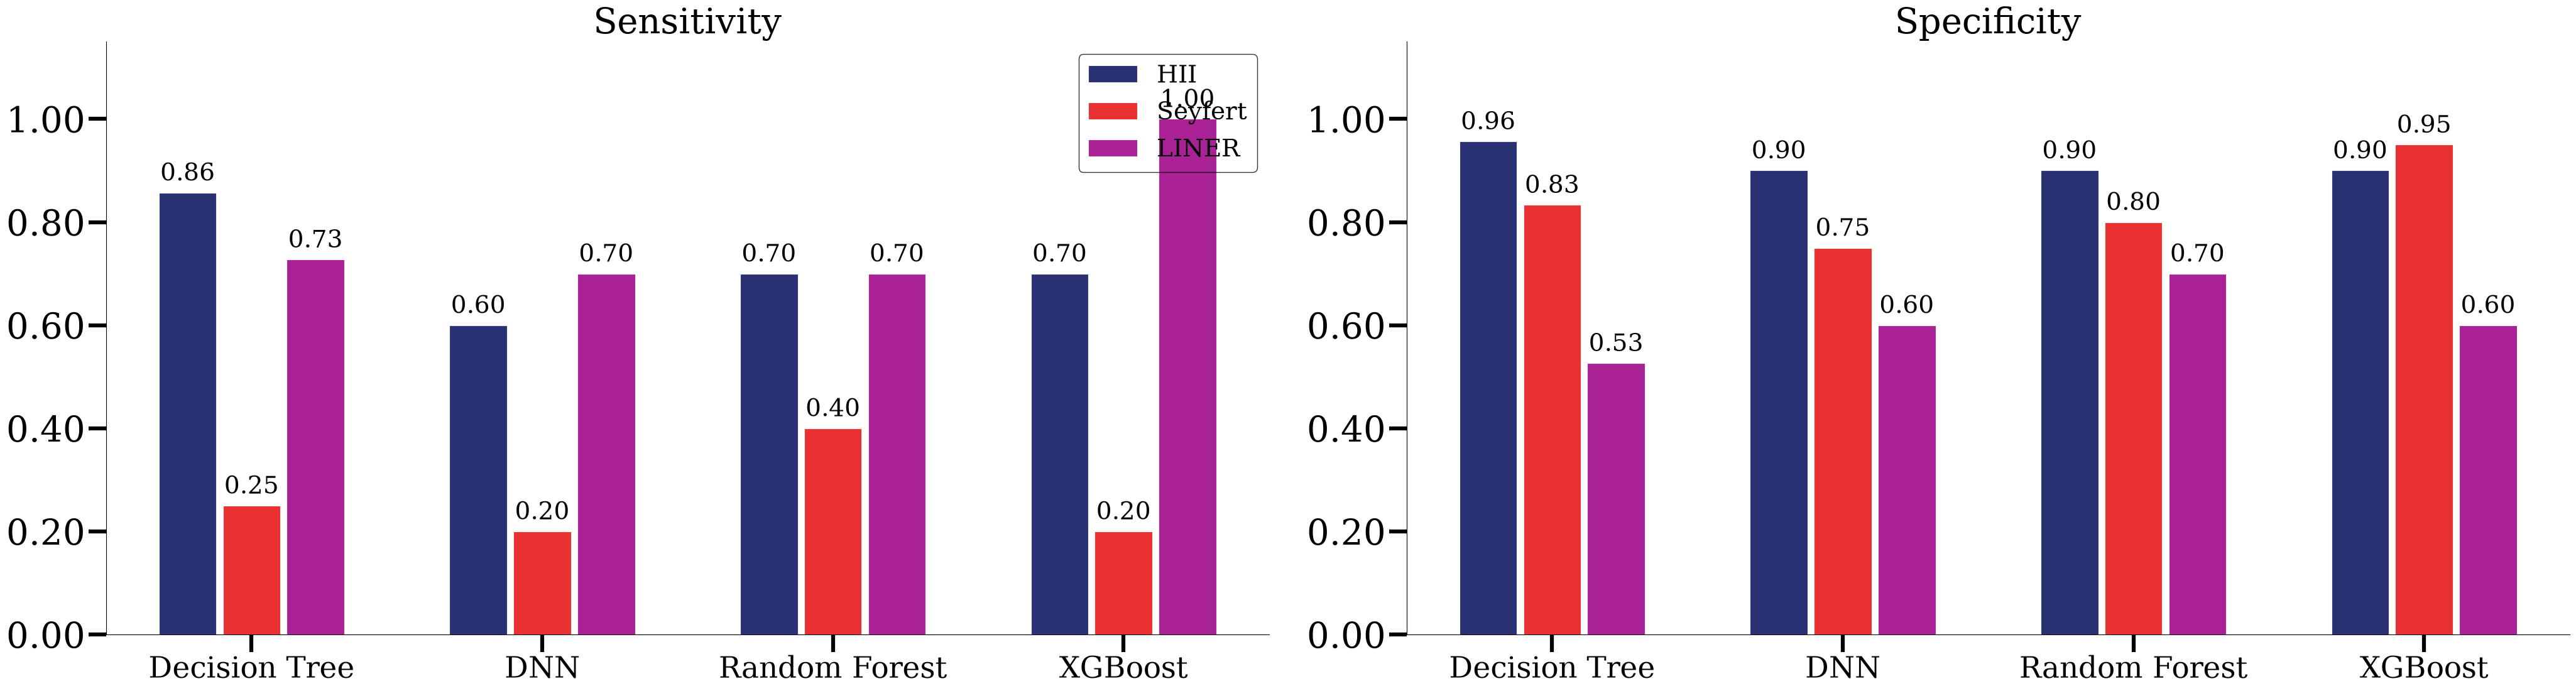

In [25]:
model_names = ["Decision Tree", "DNN", "Random Forest", "XGBoost"]
n_models    = len(model_names)
x           = np.arange(n_models)
bar_w       = 0.22    # ancho de cada grupo de barras por clase

fig, axes = plt.subplots(1, 2, figsize=(42, 12), sharey=False)
#fig.suptitle("Sensitivity and Specificity per class — all models",fontweight="bold")

offsets = np.array([-1, 0, 1]) * bar_w   # HII / Seyfert / LINER

for ax_idx, metric in enumerate(["Sensitivity", "Specificity"]):
    ax = axes[ax_idx]

    for c_idx, cls in enumerate(CLASS_NAMES):
        vals = [resultados[m][resultados[m]["Class"] == cls][metric].values[0]
                for m in model_names]

        bars = ax.bar(
            x + offsets[c_idx],
            vals,
            bar_w * 0.9,
            label=cls,
            color=CLASS_COLORS[cls],
            edgecolor="white",
            linewidth=0.8,
            alpha=0.88
        )
        for bar, v in zip(bars, vals):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.012,
                f"{v:.2f}",
                ha="center", va="bottom",
                color="black", fontsize=28
            )

    ax.set_title(metric, fontsize=40, color='black')
    ax.set_xticks(x)
    ax.set_xticklabels(model_names, ha="center", fontsize=34, color='black')
    ax.set_ylim(0, 1.15)
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.2f"))
    #ax.axhline(0.5, color="gray", linestyle="--", linewidth=0.8, alpha=0.5)
    #ax.set_ylabel(metric)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis='both', colors='black')
    for spine in ax.spines.values():
        spine.set_color('black')
    
leg = axes[0].legend(
    loc="upper right",
    fontsize=28
)

# Texto de la leyenda blanco
for text in leg.get_texts():
    text.set_color("black")

# Borde de la leyenda blanco
leg.get_frame().set_edgecolor("black")
leg.get_frame().set_facecolor("none")

plt.tight_layout()
plt.savefig(
    "imagenes/sensitivity_specificity.png",
    dpi=300,
    transparent=False,
    bbox_inches="tight",
)
plt.show()

In [26]:
print("\n% ── Tabla LaTeX ──────────────────────────────────────────────")
print(r"\begin{table}[h!]")
print(r"\centering")
print(r"\caption{Sensitivity and specificity per class for each classifier.}")
print(r"\label{tab:sens_spec}")
print(r"\begin{tabular}{llcc}")
print(r"\hline")
print(r"Model & Class & Sensitivity & Specificity \\")
print(r"\hline")

for nombre in model_names:
    df = resultados[nombre]
    for _, row in df.iterrows():
        print(
            f"{nombre} & {row['Class']} & "
            f"{row['Sensitivity']:.4f} & {row['Specificity']:.4f} \\\\"
        )
    print(r"\hline")

print(r"\end{tabular}")
print(r"\end{table}")



% ── Tabla LaTeX ──────────────────────────────────────────────
\begin{table}[h!]
\centering
\caption{Sensitivity and specificity per class for each classifier.}
\label{tab:sens_spec}
\begin{tabular}{llcc}
\hline
Model & Class & Sensitivity & Specificity \\
\hline
Decision Tree & HII & 0.8571 & 0.9565 \\
Decision Tree & Seyfert & 0.2500 & 0.8333 \\
Decision Tree & LINER & 0.7273 & 0.5263 \\
\hline
DNN & HII & 0.6000 & 0.9000 \\
DNN & Seyfert & 0.2000 & 0.7500 \\
DNN & LINER & 0.7000 & 0.6000 \\
\hline
Random Forest & HII & 0.7000 & 0.9000 \\
Random Forest & Seyfert & 0.4000 & 0.8000 \\
Random Forest & LINER & 0.7000 & 0.7000 \\
\hline
XGBoost & HII & 0.7000 & 0.9000 \\
XGBoost & Seyfert & 0.2000 & 0.9500 \\
XGBoost & LINER & 1.0000 & 0.6000 \\
\hline
\end{tabular}
\end{table}


In [27]:
data['mag_auto_r'].max()

np.float64(21.194477708816528)

In [28]:
import joblib
import numpy as np
import pandas as pd
from tensorflow.keras.models import load_model
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# --- 1. Cargar el CSV nuevo ---
nuevas_galaxias_df = pd.read_csv(r"C:\Users\amand\Desktop\tesis_ama\codes\final_results\galaxias_consistentes.csv")  # ajusta sep si no es tab

# --- 2. Seleccionar las columnas de features EN EL MISMO ORDEN que usaste para entrenar ---
# Recuerda: en tu pipeline original eran las columnas 11:23 (los 12 mag_auto_*)
feature_cols = [
    "mag_auto_r", "mag_auto_g", "mag_auto_i", "mag_auto_z", "mag_auto_u",
    "mag_auto_j0378", "mag_auto_j0395", "mag_auto_j0410", "mag_auto_j0430",
    "mag_auto_j0515", "mag_auto_j0660", "mag_auto_j0861"
]  # <-- confirma que este orden coincide exactamente con tu X original

X_new = nuevas_galaxias_df[feature_cols].to_numpy()

# --- 3. Etiquetas reales, mapeadas al mismo esquema 0/1 (HII/AGN) ---
clase_map = joblib.load("clase_map.pkl")  # {'HII': 0.0, 'AGN': 1.0}

label_col = "final_class"  # <-- ajusta al nombre real de tu columna de etiquetas

# Si tu CSV nuevo aún distingue Seyfert/LINER, primero conviértelas a "AGN"
nuevas_galaxias_df[label_col] = nuevas_galaxias_df[label_col].replace(
    {"Star-forming": "HII"}
)

Y_new_true = nuevas_galaxias_df[label_col].map(clase_map).to_numpy()

n_nan = np.isnan(Y_new_true).sum()
if n_nan > 0:
    print(f"⚠️ {n_nan} filas sin mapear — revisa valores únicos de '{label_col}'")
    print(nuevas_galaxias_df.loc[nuevas_galaxias_df[label_col].map(clase_map).isna(), label_col].unique())

# --- 4. Aplicar el MISMO scaler ya ajustado (nunca uno nuevo) ---
scaler = joblib.load("scaler.pkl")
X_new_scaled = scaler.transform(X_new)

# --- 5. Cargar los 4 modelos y predecir ---
modelo_dt  = joblib.load("modelo_dt.pkl")
modelo_rf  = joblib.load("modelo_rf.pkl")
modelo_xgb = joblib.load("modelo_xgb.pkl")
modelo_dnn = load_model("modelo_dnn.keras")

Y_pred_DT_new  = modelo_dt.predict(X_new_scaled)
Y_pred_RF_new  = modelo_rf.predict(X_new_scaled)
Y_pred_XGB_new = modelo_xgb.predict(X_new_scaled)
Y_pred_DNN_new = np.argmax(modelo_dnn.predict(X_new_scaled), axis=1)

# --- 6. Evaluar cada modelo contra las etiquetas reales ---
clase_map_inverso = joblib.load("clase_map_inverso.pkl")

for nombre, y_pred in [
    ("Decision Tree", Y_pred_DT_new),
    ("Random Forest", Y_pred_RF_new),
    ("XGBoost",       Y_pred_XGB_new),
    ("DNN",           Y_pred_DNN_new),
]:
    print(f"{nombre}: valores únicos en y_pred = {np.unique(y_pred)}")

for nombre, y_pred in [
    ("Decision Tree", Y_pred_DT_new),
    ("Random Forest", Y_pred_RF_new),
    ("XGBoost",       Y_pred_XGB_new),
    ("DNN",           Y_pred_DNN_new),
]:
    acc = accuracy_score(Y_new_true, y_pred)
    print(f"\n=== {nombre} ===")
    print(f"Accuracy en set nuevo: {acc*100:.2f}%")
    print(classification_report(
        Y_new_true, y_pred,
        target_names=[clase_map_inverso[0.0], clase_map_inverso[1.0], clase_map_inverso[2.0]]
    ))

66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Decision Tree: valores únicos en y_pred = [0. 1. 2.]
Random Forest: valores únicos en y_pred = [0. 1. 2.]
XGBoost: valores únicos en y_pred = [0 1 2]
DNN: valores únicos en y_pred = [0 1 2]

=== Decision Tree ===
Accuracy en set nuevo: 65.91%
              precision    recall  f1-score   support

         HII       0.99      0.66      0.79      1937
     Seyfert       0.11      0.65      0.19       115
       LINER       0.26      0.65      0.37        57

    accuracy                           0.66      2109
   macro avg       0.45      0.65      0.45      2109
weighted avg       0.92      0.66      0.75      2109


=== Random Forest ===
Accuracy en set nuevo: 75.44%
              precision    recall  f1-score   support

         HII       0.98      0.76      0.86      1937
     Seyfert       0.14      0.63      0.23       115
       LINER       0.43      0.70      0.53        57

    accuracy                           0.75      2109
   macro avg